# ATHENA Hackathon Day 25
## Grain-boundary ShapeNet: exact synthetic labels → learned line operators → continuous curves

This is a **self-contained, executable experiment**, not a sketch of an architecture. It creates a labeled dataset, trains a compact shape-constrained neural network, evaluates independent images, and exports a boundary graph. It also runs conventional-CNN, no-connectivity-loss, and untrained-filter comparisons.

**The central distinction:** local image evidence predicts boundary likelihood and direction; a conservative geometric decoder proposes short continuous connections. Newly added bridge pixels are explicitly recorded. Ambiguous or long gaps remain unresolved rather than being silently filled.

The data are **synthetic, not experimental microscopy**. Boundaries are straight Voronoi edges between junctions. Appearance varies in polarity, width, contrast, noise, blur, texture, and visibility. This first experiment tests the proposed line-and-continuity prior. It does not establish accuracy on real micrographs, curved boundaries, or interfaces visible only through lattice orientation.

### How to run

Run all cells in order in Jupyter or Colab. No earlier notebook, local Python module, downloaded dataset, external model, or API key is required. The source is entirely inside this notebook. GPU is used when available; the supplied run was executed on CPU.

`Config.retrain=False` reuses compatible checkpoints when the accompanying `day25_outputs/` folder is present. **Without checkpoints, training runs automatically.** Set `retrain=True` to force fresh training. The dataset is deterministically regenerated on every run. Changing dataset or architecture settings requires retraining; see the checkpoint checks below.

All figures show full fields of view. Thresholds and checkpoint epochs are selected using **validation images only**. The held-out test set is not used for model selection.

In [ ]:
# Install only missing runtime packages. This is the only optional network-dependent step.
# No data or pretrained weights are downloaded.
import importlib.util, subprocess, sys
packages = {'numpy':'numpy', 'scipy':'scipy', 'pandas':'pandas',
            'matplotlib':'matplotlib', 'skimage':'scikit-image', 'torch':'torch',
            'PIL':'Pillow', 'IPython':'ipython'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
%matplotlib inline

## 1. Configuration and reproducibility

The default experiment uses 256 training, 48 validation, 64 test, 32 stress-test, and 24 dedicated negative-control images, each 96 × 96 pixels. Every image has an independently generated geometry and a disjoint random seed. Some ordinary splits also contain no-boundary examples.

The three trained models receive the same split, initialization seed, batch order, epoch budget, optimizer, and validation-selection protocol. They are not claimed to be exactly compute-matched: the analytic front end has a larger receptive field than the CNN front end.

For a smoke test, reduce image counts and epochs **and set `retrain=True`**. For a larger experiment, increase the dataset and repeat several training seeds. Bootstrap intervals later in this notebook quantify variation across test images, not across training runs.

In [ ]:
from __future__ import annotations
import os, sys, json, time, math, random, copy, heapq, hashlib, platform, warnings
from pathlib import Path
from dataclasses import dataclass, asdict
import numpy as np
import pandas as pd
import scipy
from scipy import ndimage as ndi
from scipy.spatial import Voronoi
from scipy.optimize import linear_sum_assignment
import matplotlib
import matplotlib.pyplot as plt
import skimage
from skimage.draw import line
from skimage.morphology import skeletonize
from skimage.filters import apply_hysteresis_threshold
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from IPython.display import display

@dataclass
class Config:
    seed: int = 25
    image_size: int = 96
    n_train: int = 256
    n_val: int = 48
    n_test: int = 64
    n_stress: int = 32
    n_negative: int = 24
    epochs: int = 20
    batch_size: int = 16
    learning_rate: float = 0.002
    n_angles: int = 8
    kernel_size: int = 17
    hidden_channels: int = 24
    soft_skeleton_iterations: int = 5
    retrain: bool = False
    run_ablation: bool = True
    output_dir: str = 'day25_outputs'

CFG = Config()
OUT = Path(CFG.output_dir)
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))

def set_seed(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CFG.seed)
VERSIONS = dict(python=sys.version.split()[0], numpy=np.__version__, scipy=scipy.__version__,
                torch=torch.__version__, skimage=skimage.__version__, matplotlib=matplotlib.__version__,
                device=str(DEVICE))
print('Runtime:', VERSIONS)
print('Configuration:', asdict(CFG))

Runtime: {'python': '3.13.16', 'numpy': '2.4.6', 'scipy': '1.16.3', 'torch': '2.14.1+cu130', 'skimage': '0.25.2', 'matplotlib': '3.10.0', 'device': 'cuda'}
Configuration: {'seed': 25, 'image_size': 96, 'n_train': 256, 'n_val': 48, 'n_test': 64, 'n_stress': 32, 'n_negative': 24, 'epochs': 20, 'batch_size': 16, 'learning_rate': 0.002, 'n_angles': 8, 'kernel_size': 17, 'hidden_channels': 24, 'soft_skeleton_iterations': 5, 'retrain': False, 'run_ablation': True, 'output_dir': 'day25_outputs'}


## 2. Ground truth is defined before image formation

We generate a planar Voronoi partition and clip its exact vector edges to the image domain. Interior graph nodes are junctions; boundaries may terminate at the field-of-view edge. The exterior image rectangle is **not** itself labeled as a grain boundary. Remote guard points make Voronoi ridges finite without changing the partition inside the crop.

For an edge from $\mathbf a$ to $\mathbf b$, the distance from each pixel to the finite segment is computed analytically. The label is a fixed-width band with distance ≤ 1.2 pixels; its morphological skeleton supplies the centerline target. Grain identities come directly from nearest-seed assignment. Junction targets are Gaussian peaks centered on exact geometric junctions.

The undirected tangent is represented as

$$\mathbf q=(\cos 2\theta,\sin 2\theta),$$

so that reversing a line does not change its target. Orientation supervision is disabled within four pixels of junctions, where a unique direction is not defined. The orientation map stores the nearest edge's direction elsewhere.

Image formation is independent of labeling: boundary width and contrast vary; either bright or dark boundaries are rendered; noise, weak grain offsets, background drift, and finite line distractors are added. Random short sections are attenuated without deleting their ground-truth boundary. The `gap` label identifies the hidden centerline pixels specifically.

**Identifiability limitation:** a sufficiently obscured segment is not directly observable. Its reconstruction is an inference from context, not new measured evidence. The stress split intentionally uses longer gaps and stronger noise than the training distribution.

In [ ]:
def clip_segment(a, b, width, height):
    """Liang–Barsky clipping to pixel-center domain [0,W-1] x [0,H-1]."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = b-a; lo, hi = 0., 1.
    for k, upper in [(0, width-1.), (1, height-1.)]:
        if abs(d[k]) < 1e-10:
            if a[k] < 0 or a[k] > upper: return None
        else:
            t0, t1 = -a[k]/d[k], (upper-a[k])/d[k]
            lo, hi = max(lo, min(t0,t1)), min(hi, max(t0,t1))
            if lo > hi: return None
    aa, bb = a+lo*d, a+hi*d
    return (aa, bb) if np.linalg.norm(bb-aa) > .2 else None


def grain_geometry(rng, size, n_grains):
    """Return a planar, clipped Voronoi graph; no image thresholding produces labels."""
    seeds=[]
    for _ in range(n_grains):
        for attempt in range(1000):
            p=rng.uniform(2, size-3, 2)
            if not seeds or min(np.linalg.norm(p-q) for q in seeds) > size*.085: break
        seeds.append(p)
    seeds=np.asarray(seeds)
    # Remote guards make all relevant ridges finite without changing the diagram in the crop.
    s=float(size)
    guards=np.array([[-20*s,-20*s],[-20*s,21*s],[21*s,-20*s],[21*s,21*s]])
    vor=Voronoi(np.vstack([seeds,guards]))
    nodes=[]; edges=[]
    def node_id(p):
        for i,q in enumerate(nodes):
            if np.linalg.norm(p-q)<1e-4: return i
        nodes.append(p); return len(nodes)-1
    for (i,j), vertices in zip(vor.ridge_points,vor.ridge_vertices):
        if i>=len(seeds) or j>=len(seeds) or -1 in vertices: continue
        seg=clip_segment(vor.vertices[vertices[0]],vor.vertices[vertices[1]],size,size)
        if seg is None: continue
        a,b=seg
        edges.append(dict(nodes=[node_id(a),node_id(b)], grains=[int(i+1),int(j+1)]))
    nodes=np.asarray(nodes)
    degrees=np.zeros(len(nodes),int)
    for e in edges:
        degrees[e['nodes']]+=1
    border=np.any((nodes<1e-4)|(nodes>size-1-1e-4),axis=1)
    junctions=np.where((degrees>=3)&~border)[0]
    assert np.all((degrees>=2)|border), 'Unexpected dangling endpoint in ground truth.'
    return dict(seeds=seeds.tolist(),nodes=nodes.tolist(),edges=edges,
                junction_nodes=junctions.tolist(),border_nodes=np.flatnonzero(border).tolist())


def make_sample(seed: int, size: int=96, stress: bool=False, negative: bool=False):
    rng=np.random.default_rng(seed)
    yy,xx=np.mgrid[:size,:size].astype(float)
    negative=negative or (not stress and rng.random()<.07)
    graph=(dict(seeds=[],nodes=[],edges=[],junction_nodes=[],border_nodes=[])
           if negative else grain_geometry(rng,size,int(rng.integers(8,17))))
    nodes=np.asarray(graph['nodes'])
    min_dist=np.full((size,size),np.inf)
    theta=np.zeros((size,size)); edge_id=np.full((size,size),-1,np.int16)
    signal=np.zeros((size,size)); all_gap=np.zeros((size,size),bool)
    image_polarity=rng.choice([-1.,1.])
    width_scale=rng.uniform(.65,1.35) if not stress else rng.uniform(.6,1.8)
    contrast=rng.uniform(.24,.4) if not stress else rng.uniform(.15,.30)
    segment_data=[]
    for eid,e in enumerate(graph['edges']):
        a,b=nodes[e['nodes']]; d=b-a; length_=np.linalg.norm(d)
        t=((xx-a[0])*d[0]+(yy-a[1])*d[1])/(length_**2)
        tclip=np.clip(t,0,1)
        dist=np.hypot(xx-a[0]-tclip*d[0],yy-a[1]-tclip*d[1])
        nearest=dist<min_dist
        min_dist[nearest]=dist[nearest]; edge_id[nearest]=eid
        theta[nearest]=np.arctan2(d[1],d[0])
        sigma=width_scale*rng.uniform(.85,1.15)
        strength=rng.uniform(.75,1.0)
        profile=strength*np.exp(-.5*(dist/sigma)**2)
        attenuation=np.ones_like(profile)
        gap_ranges=[]
        if length_>15 and rng.random() < (.30 if not stress else .55):
            gaplen=rng.uniform(3.5,8.) if not stress else rng.uniform(8.,14.)
            gaplen=min(gaplen,length_*.5)
            center=rng.uniform(.30,.70)*length_
            # Smooth loss of visibility; the label geometry is unchanged.
            gap=np.abs(t*length_-center) < gaplen/2
            attenuation[gap]=rng.uniform(.0,.12)
            all_gap |= gap & (dist<=1.2)
            gap_ranges.append([float((center-gaplen/2)/length_),float((center+gaplen/2)/length_)])
        signal=np.maximum(signal, profile*attenuation)
        segment_data.append(dict(length=float(length_),width=float(sigma),hidden_ranges=gap_ranges))
    if not negative:
        seeds=np.asarray(graph['seeds'])
        grain=np.argmin((xx[...,None]-seeds[:,0])**2+(yy[...,None]-seeds[:,1])**2,axis=-1).astype(np.int16)+1
        # Subtle grain contrast, deliberately much weaker than boundary contrast.
        offsets=rng.normal(0,.012 if not stress else .02,len(seeds))
        grain_background=offsets[grain-1]
    else:
        grain=np.ones((size,size),np.int16); grain_background=np.zeros((size,size))
    background=ndi.gaussian_filter(rng.normal(size=(size,size)),size/10)
    background=background/(background.std()+1e-6)*rng.uniform(.005,.022)
    texture=ndi.gaussian_filter(rng.normal(size=(size,size)),rng.uniform(.7,1.4))
    texture=texture/(texture.std()+1e-6)*rng.uniform(.003,.015)
    # Faint finite line distractors are NOT boundaries. Hard negatives test over-connection.
    distractor=np.zeros((size,size))
    n_distractors=int(rng.integers(0,3)) if not negative else int(rng.integers(1,5))
    for _ in range(n_distractors):
        a=rng.uniform(6,size-6,2); ang=rng.uniform(0,np.pi)
        b=np.clip(a+rng.uniform(6,20)*np.array([np.cos(ang),np.sin(ang)]),2,size-3)
        d=b-a; t=np.clip(((xx-a[0])*d[0]+(yy-a[1])*d[1])/(np.dot(d,d)+1e-8),0,1)
        dist=np.hypot(xx-a[0]-t*d[0],yy-a[1]-t*d[1])
        distractor+=rng.choice([-1.,1.])*rng.uniform(.025,.11)*np.exp(-.5*(dist/rng.uniform(.6,1.2))**2)
    noise_sigma=rng.uniform(.018,.065) if not stress else rng.uniform(.07,.115)
    image=.50+grain_background+background+texture+image_polarity*contrast*signal+distractor
    image=ndi.gaussian_filter(image,rng.uniform(.0,.45))
    image+=rng.normal(0,noise_sigma,(size,size))
    image=np.clip(image,0,1).astype(np.float32)
    boundary=min_dist<=1.2
    centerline=skeletonize(boundary)
    junction=np.zeros((size,size),np.float32)
    junction_dist=np.full((size,size),np.inf)
    for idx in graph['junction_nodes']:
        p=nodes[idx]; d=np.hypot(xx-p[0],yy-p[1]); junction_dist=np.minimum(junction_dist,d)
        junction=np.maximum(junction,np.exp(-.5*(d/1.3)**2))
    orientation=np.stack([np.cos(2*theta),np.sin(2*theta)]).astype(np.float32)
    valid=boundary & (junction_dist>4.)
    orientation[:,~valid]=0
    # Only entirely suppressed centerline pixels count as hidden-gap ground truth.
    gap=all_gap & centerline
    graph.update(seed=int(seed),negative=bool(negative),stress=bool(stress),segments=segment_data,
                 noise_sigma=float(noise_sigma),polarity=float(image_polarity),contrast=float(contrast))
    return dict(image=image,boundary=boundary.astype(np.uint8),centerline=centerline.astype(np.uint8),
                orientation=orientation,orientation_valid=valid.astype(np.uint8),junction=junction,
                grain=grain,edge_id=edge_id,gap=gap.astype(np.uint8)), graph


def make_split(n, offset, stress=False, negative=False):
    samples=[]; graphs=[]
    for i in range(n):
        sample,graph=make_sample(CFG.seed+offset+i,CFG.image_size,stress,negative)
        samples.append(sample); graphs.append(graph)
    arrays={k:np.stack([s[k] for s in samples]) for k in samples[0]}
    arrays['seed']=np.array([g['seed'] for g in graphs],np.int64)
    arrays['negative']=np.array([g['negative'] for g in graphs],bool)
    return arrays,graphs


def generate_datasets():
    datasets={}; geometries={}
    for name,n,offset,stress,negative in [
        ('train',CFG.n_train,100_000,False,False),('val',CFG.n_val,200_000,False,False),
        ('test',CFG.n_test,300_000,False,False),('stress',CFG.n_stress,400_000,True,False),
        ('negative',CFG.n_negative,500_000,False,True)]:
        data,graphs=make_split(n,offset,stress,negative)
        datasets[name]=data; geometries[name]=graphs
        np.savez_compressed(OUT/f'{name}.npz',**data)
        (OUT/f'{name}_geometry.json').write_text(json.dumps(graphs))
        print(f'{name:8s}: {n} independent images; {sum(data["negative"])} no-boundary examples',flush=True)
    seeds=[set(d['seed'].tolist()) for d in datasets.values()]
    assert all(not seeds[i]&seeds[j] for i in range(len(seeds)) for j in range(i))
    (OUT/'config.json').write_text(json.dumps(asdict(CFG),indent=2))
    (OUT/'versions.json').write_text(json.dumps(VERSIONS,indent=2))
    return datasets,geometries

In [ ]:
DATA, GEOMETRY = generate_datasets()
manifest = []
for split, d in DATA.items():
    manifest.append({'split': split, 'images': len(d['image']),
                     'size': str(d['image'].shape[1:]),
                     'no_boundary_images': int(d['negative'].sum()),
                     'images_with_hidden_gaps': int(d['gap'].any(axis=(1,2)).sum()),
                     'boundary_pixel_fraction': float(d['boundary'].mean())})
manifest = pd.DataFrame(manifest)
manifest.to_csv(OUT/'dataset_manifest.csv', index=False)
display(manifest)

train   : 256 independent images; 16 no-boundary examples
val     : 48 independent images; 2 no-boundary examples
test    : 64 independent images; 4 no-boundary examples
stress  : 32 independent images; 0 no-boundary examples
negative: 24 independent images; 24 no-boundary examples


,split,images,size,no_boundary_images,images_with_hidden_gaps,boundary_pixel_fraction
0,train,256,"(96, 96)",16,239,0.116421
1,val,48,"(96, 96)",2,46,0.120122
2,test,64,"(96, 96)",4,60,0.112452
3,stress,32,"(96, 96)",0,32,0.125936
4,negative,24,"(96, 96)",24,0,0.000000


### Dataset schema

Each split is saved as an ordinary compressed NumPy file (`train.npz`, `val.npz`, etc.) that can be read with `np.load(..., allow_pickle=False)`.

| Array | Shape | Meaning |
|---|---|---|
| `image` | N × H × W | Float32 input in [0,1] |
| `boundary` | N × H × W | Complete binary boundary band |
| `centerline` | N × H × W | One-pixel skeleton of that band |
| `orientation` | N × 2 × H × W | Doubled-angle tangent components |
| `orientation_valid` | N × H × W | Orientation-supervision mask |
| `junction` | N × H × W | Gaussian junction target |
| `grain` | N × H × W | Grain identity (1-based) |
| `edge_id` | N × H × W | Nearest vector-edge index; −1 on negative images |
| `gap` | N × H × W | Hidden centerline pixels retained in the complete target |
| `seed`, `negative` | N | Reproducibility and negative-control flags |

The corresponding `*_geometry.json` files contain seeds, nodes, border nodes, junctions, edges, adjacent grain identities, contrast, polarity, noise level, segment widths, and hidden intervals. Vector coordinates use **(x,y)**; raster graph paths later use **(row,column)**.

In [ ]:
def show_image(array, title, filename=None, vmin=None, vmax=None):
    """One complete image per figure. No crop is used to hide failures."""
    fig,ax=plt.subplots(figsize=(5.8,5.2))
    im=ax.imshow(array,vmin=vmin,vmax=vmax)
    ax.set_title(title); ax.set_xlabel('x (pixels)'); ax.set_ylabel('y (pixels)')
    fig.colorbar(im,ax=ax,fraction=.046,pad=.04)
    fig.tight_layout()
    if filename: fig.savefig(OUT/filename,dpi=130,bbox_inches='tight')
    plt.show(); plt.close(fig)

class GrainDataset(Dataset):
    def __init__(self, data): self.data=data
    def __len__(self): return len(self.data['image'])
    def __getitem__(self,i):
        # Center on a fixed physical intensity, NOT on a ground-truth-derived statistic.
        x=torch.from_numpy((self.data['image'][i:i+1]-.5)*4.)
        y={k:torch.from_numpy(self.data[k][i].astype(np.float32)) for k in
           ['boundary','centerline','orientation','orientation_valid','junction']}
        for k in ['boundary','centerline','orientation_valid','junction']: y[k]=y[k][None]
        return x,y

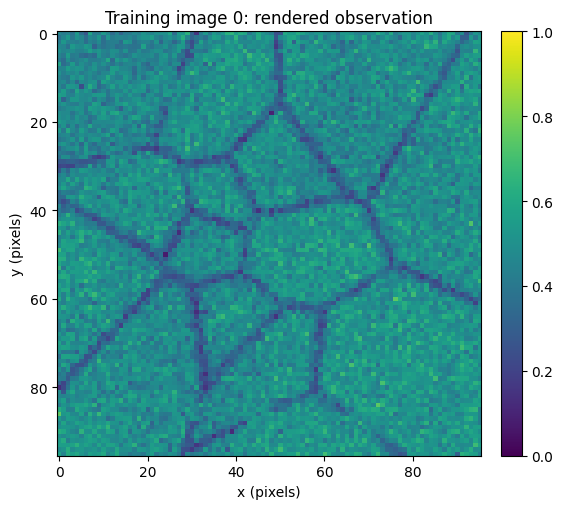

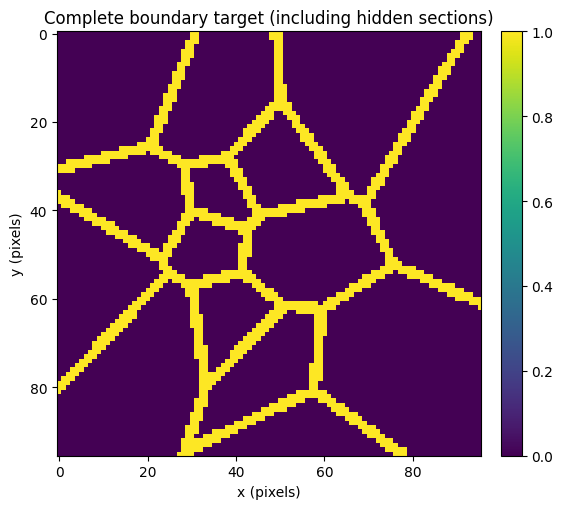

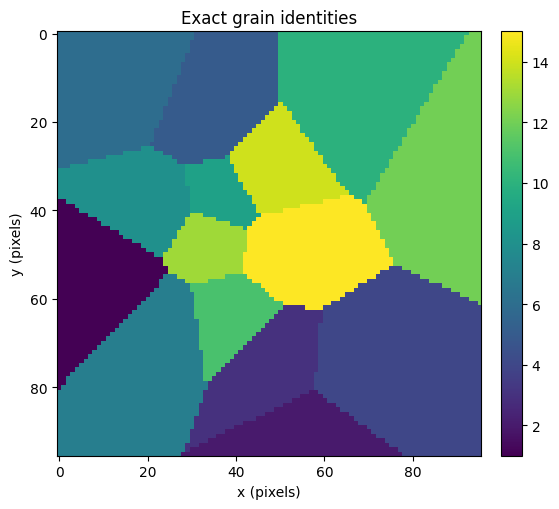

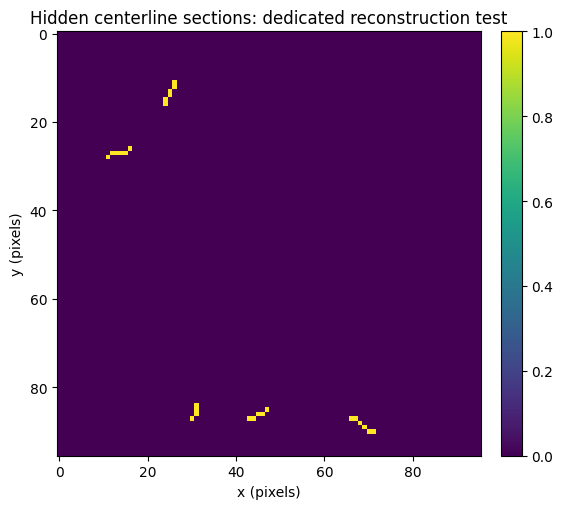

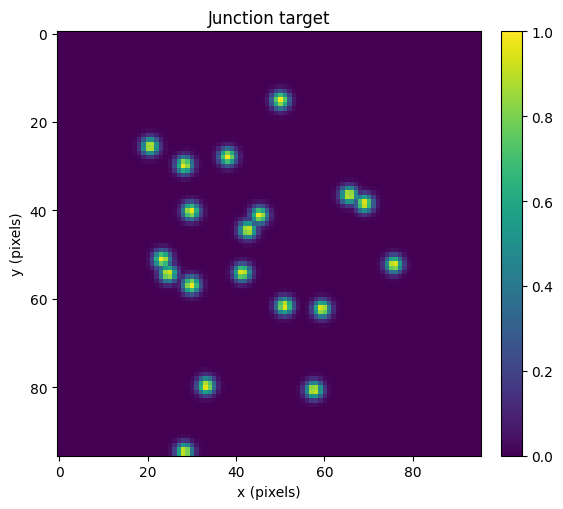

In [ ]:
EXAMPLE = int(np.flatnonzero(~DATA['train']['negative'])[0])
d = DATA['train']
show_image(d['image'][EXAMPLE], f'Training image {EXAMPLE}: rendered observation', 'example_input.png', 0, 1)
show_image(d['boundary'][EXAMPLE], 'Complete boundary target (including hidden sections)', 'example_boundary.png', 0, 1)
show_image(d['grain'][EXAMPLE], 'Exact grain identities', 'example_grains.png')
show_image(d['gap'][EXAMPLE], 'Hidden centerline sections: dedicated reconstruction test', 'example_gaps.png', 0, 1)
show_image(d['junction'][EXAMPLE], 'Junction target', 'example_junctions.png', 0, 1)

## 3. A shape-constrained, differentiable front end

For tangent and transverse coordinates

$$u=x\cos\theta+y\sin\theta,\qquad v=-x\sin\theta+y\cos\theta,$$

the basic line operator is

$$K_{\theta,\sigma,\ell}(x,y)\propto
\left(1-\frac{v^2}{\sigma^2}\right)
\exp\!\left[-\frac{u^2}{2\ell^2}-\frac{v^2}{2\sigma^2}\right].$$

Finite-support DC leakage is removed using the same localized envelope, and every filter is normalized to unit energy. Kernel pixels are **not independent trainable weights**. Backpropagation adjusts bounded angles, widths, and lengths. Angles may move within half an orientation-bin spacing, preserving coverage of the orientation circle.

The CPU-portable default has **8 orientations × 2 widths × 2 lengths = 32 analytic filters**, each 17 × 17 pixels. Both contrast polarities and the magnitude response aggregated along the corresponding tangent are retained: 96 feature channels. This is a smaller implementation of the earlier proposed 72-filter bank; `n_angles` is configurable.

The readout uses a 1 × 1 mixer and four compact 3 × 3 convolutions in two residual blocks. It predicts boundary logits, the two-component tangent, and junction logits at full image resolution. It does not use an encoder–decoder bottleneck or downsample thin interfaces.

The CNN baseline replaces the analytic bank by an ordinary learned 7 × 7 first layer while retaining the same readout and output heads. It is an architectural comparison, not proof that one family is universally superior.

In [ ]:
class AnalyticLineBank(nn.Module):
    """The kernels remain line detectors: only angle, width and length are learned."""
    def __init__(self,n_angles=8,kernel_size=17,learnable=True):
        super().__init__(); self.n_angles=n_angles; self.kernel_size=kernel_size
        combos=[(i,s,l) for i in range(n_angles) for s in (.75,1.35) for l in (2.3,4.3)]
        self.register_buffer('angle_index',torch.tensor([c[0] for c in combos]))
        self.register_buffer('base_angle',torch.arange(n_angles)*math.pi/n_angles)
        self.angle_offset=nn.Parameter(torch.zeros(n_angles),requires_grad=learnable)
        self.raw_sigma=nn.Parameter(torch.tensor([self.inv(c[1],.45,2.4) for c in combos]),requires_grad=learnable)
        self.raw_length=nn.Parameter(torch.tensor([self.inv(c[2],1.5,6.0) for c in combos]),requires_grad=learnable)
        y,x=torch.meshgrid(torch.arange(kernel_size)-kernel_size//2,torch.arange(kernel_size)-kernel_size//2,indexing='ij')
        self.register_buffer('xx',x.float()); self.register_buffer('yy',y.float())
    @staticmethod
    def inv(value,lo,hi):
        p=(value-lo)/(hi-lo); return math.log(p/(1-p))
    def parameters_physical(self):
        angles=self.base_angle+math.pi/(2*self.n_angles)*torch.tanh(self.angle_offset)
        return angles[self.angle_index],.45+1.95*torch.sigmoid(self.raw_sigma),1.5+4.5*torch.sigmoid(self.raw_length)
    def kernels(self):
        theta,sigma,length_=self.parameters_physical()
        t=theta[:,None,None]; s=sigma[:,None,None]; l=length_[:,None,None]
        u=self.xx*torch.cos(t)+self.yy*torch.sin(t)
        v=-self.xx*torch.sin(t)+self.yy*torch.cos(t)
        env=torch.exp(-.5*((u/l)**2+(v/s)**2))
        raw=(1-(v/s)**2)*env
        # Remove finite-support DC leakage using the same localized envelope.
        raw=raw-raw.sum((-2,-1),keepdim=True)/(env.sum((-2,-1),keepdim=True)+1e-8)*env
        line_kernel=raw/torch.sqrt((raw**2).sum((-2,-1),keepdim=True)+1e-8)
        # Smooth aggregation ALONG the same direction, narrow across it.
        agg=torch.exp(-.5*((u/(l*1.5))**2+(v/.7)**2))
        agg=agg/(agg.sum((-2,-1),keepdim=True)+1e-8)
        return line_kernel[:,None],agg[:,None]
    def forward(self,x):
        k,a=self.kernels(); p=self.kernel_size//2
        r=F.conv2d(F.pad(x,(p,p,p,p),mode='reflect'),k)
        pos,neg=F.relu(r),F.relu(-r)
        # Keep both polarities and orientations; never take an early max over orientation.
        mag=pos+neg
        along=F.conv2d(F.pad(mag,(p,p,p,p),mode='reflect'),a,groups=len(a))
        return torch.cat([pos,neg,along],dim=1)

class ResidualReadout(nn.Module):
    def __init__(self,channels,dilation=1):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(channels,channels,3,padding=dilation,dilation=dilation),
                               nn.GroupNorm(4,channels),nn.SiLU(),
                               nn.Conv2d(channels,channels,3,padding=1),nn.GroupNorm(4,channels))
    def forward(self,x): return F.silu(x+self.net(x))

class GrainShapeNet(nn.Module):
    def __init__(self,kind='shape',learnable=True):
        super().__init__(); self.kind=kind; h=CFG.hidden_channels
        if kind=='shape':
            self.bank=AnalyticLineBank(CFG.n_angles,CFG.kernel_size,learnable)
            self.front=nn.Sequential(nn.Conv2d(CFG.n_angles*4*3+1,h,1),nn.GroupNorm(4,h),nn.SiLU())
        elif kind=='cnn':
            self.front=nn.Sequential(nn.Conv2d(1,h,7,padding=3),nn.GroupNorm(4,h),nn.SiLU())
        else: raise ValueError(kind)
        self.body=nn.Sequential(ResidualReadout(h,1),ResidualReadout(h,2))
        self.boundary=nn.Conv2d(h,1,1); self.orientation=nn.Conv2d(h,2,1); self.junction=nn.Conv2d(h,1,1)
        nn.init.constant_(self.boundary.bias,-1.5); nn.init.constant_(self.junction.bias,-3.)
    def forward(self,x):
        z=self.front(torch.cat([x,self.bank(x)],1) if self.kind=='shape' else x)
        z=self.body(z)
        q=F.normalize(self.orientation(z),dim=1,eps=1e-6)
        return dict(boundary_logits=self.boundary(z),orientation=q,junction_logits=self.junction(z))

In [ ]:
for kind in ['shape', 'cnn']:
    model_description = GrainShapeNet(kind)
    print(kind, 'parameters:', sum(p.numel() for p in model_description.parameters()),
          '; trainable:', sum(p.numel() for p in model_description.parameters() if p.requires_grad))
    if kind == 'shape':
        print('Analytic geometric parameters:', sum(p.numel() for p in model_description.bank.parameters()))
del model_description

shape parameters: 23596 ; trainable: 23596
Analytic geometric parameters: 72
cnn parameters: 22372 ; trainable: 22372


## 4. Training objective

The implemented objective is

$$\mathcal L=0.6\mathcal L_{\mathrm{weighted\ BCE}}
+\mathcal L_{\mathrm{Dice}}
+0.35\mathcal L_{\mathrm{soft\text{-}clDice}}
+0.15\mathcal L_{\mathrm{orientation}}
+0.12\mathcal L_{\mathrm{junction}}.$$

The orientation term is $1-\hat{\mathbf q}\cdot\mathbf q$ on valid target pixels. Rare boundary and junction pixels receive positive-class weighting. The no-connectivity ablation sets only the soft-clDice coefficient to zero.

Soft-clDice compares differentiable skeleton overlap as well as ordinary segmentation overlap. This implementation follows the pooling-based soft erosion/opening/skeletonization idea in [Shit et al., CVPR 2021](https://openaccess.thecvf.com/content/CVPR2021/html/Shit_clDice_-_A_Novel_Topology-Preserving_Loss_Function_for_Tubular_Structure_CVPR_2021_paper.html) and the [authors' implementation](https://github.com/jocpae/clDice). Empty targets are excluded from the connectivity term but remain in the pixel losses, so no-boundary images still teach suppression of false positives.

**Soft-clDice is a training preference, not a hard guarantee of correct topology after thresholding.** We therefore report unresolved ends, gap recall, edge coverage and false inferred bridges separately. The data, loss, and decoder serve different roles.

In [ ]:
def soft_erode(x):
    return torch.minimum(-F.max_pool2d(-x,(3,1),1,(1,0)),-F.max_pool2d(-x,(1,3),1,(0,1)))

def soft_skeleton(x,iterations=5):
    opened=F.max_pool2d(soft_erode(x),3,1,1)
    skel=F.relu(x-opened)
    for _ in range(iterations):
        x=soft_erode(x)
        delta=F.relu(x-F.max_pool2d(soft_erode(x),3,1,1))
        skel=skel+F.relu(delta-skel*delta)
    return skel


def loss_function(output,y,connectivity_weight=.35):
    logits=output['boundary_logits']; p=torch.sigmoid(logits); gt=y['boundary']; axes=(1,2,3)
    bce=F.binary_cross_entropy_with_logits(logits,gt,pos_weight=torch.tensor(3.,device=logits.device))
    dice=(1-(2*(p*gt).sum(axes)+1)/((p+gt).sum(axes)+1)).mean()
    if connectivity_weight:
        ps=soft_skeleton(p,CFG.soft_skeleton_iterations)
        # Target skeleton is computed from target segmentation, matching soft-clDice.
        with torch.no_grad(): gs=soft_skeleton(gt,CFG.soft_skeleton_iterations)
        tp=((ps*gt).sum(axes)+1e-5)/(ps.sum(axes)+1e-5)
        ts=((gs*p).sum(axes)+1e-5)/(gs.sum(axes)+1e-5)
        positive=(gt.sum(axes)>0)
        cl=(1-2*tp*ts/(tp+ts+1e-5))[positive].mean() if positive.any() else p.sum()*0.
    else: cl=p.sum()*0.
    valid=y['orientation_valid']
    dot=(output['orientation']*y['orientation']).sum(1,keepdim=True)
    ori=((1-dot)*valid).sum()/(valid.sum()+1)
    # Gaussian junction target; increased positive weight for rare local junctions.
    jl=F.binary_cross_entropy_with_logits(output['junction_logits'],y['junction'],
                                         pos_weight=torch.tensor(15.,device=logits.device))
    total=.6*bce+dice+connectivity_weight*cl+.15*ori+.12*jl
    return total,dict(loss=total.item(),bce=bce.item(),dice=dice.item(),cldice=cl.item(),orientation=ori.item(),junction=jl.item())

## 5. Training, checkpoint selection, and basic metrics

All three models in the supplied deliverable were trained from scratch during preparation. The saved executed notebook reloads those checkpoints and reruns generation and evaluation; epoch histories and the original training transcript are included. Set `retrain=True` to repeat optimization within the notebook.

Checkpoints are chosen by the lowest validation objective for each model. No test-set score determines an epoch, threshold, or model setting. The sigmoid boundary output is called a *score*: this notebook does not establish probabilistic calibration or epistemic uncertainty.

The topology ablation has a different validation objective, so its loss-curve height must not be interpreted as a cross-model ranking. Performance is compared using the same held-out evaluation metrics.

In [ ]:
def segmentation_metrics(pred,gt,gt_skeleton,tol=2.):
    pred=pred.astype(bool); gt=gt.astype(bool); gs=gt_skeleton.astype(bool)
    if not gt.any():
        empty=float(not pred.any())
        return dict(dice=empty,centerline_precision=empty,centerline_recall=empty,centerline_f1=empty,cldice=empty)
    dice=2*np.logical_and(pred,gt).sum()/max(1,pred.sum()+gt.sum())
    ps=skeletonize(pred)
    dg=ndi.distance_transform_edt(~gs)
    dp=ndi.distance_transform_edt(~ps) if ps.any() else np.full(gs.shape,np.inf)
    prec=float((dg[ps]<=tol).mean()) if ps.any() else 0.
    recall=float((dp[gs]<=tol).mean())
    f1=2*prec*recall/(prec+recall+1e-8)
    tprec=float(gt[ps].mean()) if ps.any() else 0.
    tsens=float(pred[gs].mean())
    cl=2*tprec*tsens/(tprec+tsens+1e-8)
    return dict(dice=float(dice),centerline_precision=prec,centerline_recall=recall,centerline_f1=f1,cldice=cl)

@torch.no_grad()
def predict_model(model,data,batch_size=16):
    model.eval(); result={k:[] for k in ['probability','orientation','junction']}
    for start in range(0,len(data['image']),batch_size):
        x=torch.from_numpy((data['image'][start:start+batch_size,None]-.5)*4.).to(DEVICE)
        output=model(x)
        result['probability'].append(torch.sigmoid(output['boundary_logits']).cpu().numpy()[:,0])
        result['orientation'].append(output['orientation'].cpu().numpy())
        result['junction'].append(torch.sigmoid(output['junction_logits']).cpu().numpy()[:,0])
    return {k:np.concatenate(v) for k,v in result.items()}


def train_one(name,train_data,val_data,kind='shape',connectivity_weight=.35,learnable=True):
    set_seed(CFG.seed)
    model=GrainShapeNet(kind,learnable).to(DEVICE)
    checkpoint=OUT/f'{name}.pt'; history_path=OUT/f'{name}_history.csv'
    initial=[v.detach().clone() for v in model.bank.parameters_physical()] if kind=='shape' else None
    if not CFG.retrain and checkpoint.exists():
        saved=torch.load(checkpoint,map_location=DEVICE,weights_only=False)
        expected = ['seed','image_size','n_train','n_val','n_angles','kernel_size','hidden_channels']
        mismatches = [k for k in expected if saved['config'].get(k) != asdict(CFG)[k]]
        if mismatches or saved['kind'] != kind:
            raise ValueError(f'Checkpoint/config mismatch: {mismatches}. Set retrain=True.')
        model.load_state_dict(saved['model']); print('Loaded',checkpoint,'; validation-selected epoch',saved['epoch'])
        return model,pd.read_csv(history_path),saved.get('initial_geometry')
    loader=DataLoader(GrainDataset(train_data),batch_size=CFG.batch_size,shuffle=True,
                      num_workers=0,generator=torch.Generator().manual_seed(CFG.seed))
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.learning_rate,weight_decay=1e-4)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=CFG.epochs,eta_min=2e-4)
    best=float('inf'); history=[]; started=time.time(); best_epoch=0
    initial_np=[v.detach().cpu().numpy() for v in initial] if initial is not None else None
    for epoch in range(1,CFG.epochs+1):
        model.train(); sums={}; n=0
        for x,y in loader:
            x=x.to(DEVICE); y={k:v.to(DEVICE) for k,v in y.items()}
            opt.zero_grad(set_to_none=True)
            output=model(x); loss,parts=loss_function(output,y,connectivity_weight)
            if not torch.isfinite(loss): raise RuntimeError('Nonfinite loss; inspect data/learning rate.')
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),5.)
            opt.step()
            n+=len(x)
            for k,v in parts.items(): sums[k]=sums.get(k,0)+v*len(x)
        model.eval(); val_loss=0.; count=0
        with torch.no_grad():
            for x,y in DataLoader(GrainDataset(val_data),batch_size=CFG.batch_size):
                x=x.to(DEVICE); y={k:v.to(DEVICE) for k,v in y.items()}
                lv,_=loss_function(model(x),y,connectivity_weight)
                val_loss+=float(lv)*len(x); count+=len(x)
        val_loss/=count
        record=dict(epoch=epoch,**{k:v/n for k,v in sums.items()},val_loss=val_loss,
                    lr=opt.param_groups[0]['lr'],elapsed_seconds=time.time()-started)
        history.append(record)
        if val_loss<best:
            best=val_loss; best_epoch=epoch
            torch.save(dict(model={k:v.detach().cpu() for k,v in model.state_dict().items()},
                            config=asdict(CFG),kind=kind,name=name,epoch=epoch,
                            validation_loss=best,initial_geometry=initial_np),checkpoint)
        scheduler.step()
        print(f'{name:20s} epoch {epoch:02d}/{CFG.epochs}: train={record["loss"]:.4f} val={val_loss:.4f} elapsed={time.time()-started:.0f}s',flush=True)
    pd.DataFrame(history).to_csv(history_path,index=False)
    model.load_state_dict(torch.load(checkpoint,map_location=DEVICE,weights_only=False)['model'])
    print(f'Using {name}: validation-selected epoch {best_epoch}; {sum(p.numel() for p in model.parameters()):,} parameters.')
    return model,pd.DataFrame(history),initial_np

In [ ]:
MODELS, HISTORIES, INITIAL_GEOMETRY = {}, {}, {}
experiments = [('shapenet', 'shape', .35)]
if CFG.run_ablation:
    experiments += [('cnn', 'cnn', .35), ('shape_no_cldice', 'shape', 0.)]
for name, kind, connectivity_weight in experiments:
    model, history, initial = train_one(name, DATA['train'], DATA['val'],
                                       kind=kind, connectivity_weight=connectivity_weight)
    MODELS[name], HISTORIES[name], INITIAL_GEOMETRY[name] = model, history, initial

shapenet             epoch 01/20: train=1.0588 val=0.6676 elapsed=3s
shapenet             epoch 02/20: train=0.5449 val=0.3978 elapsed=4s
shapenet             epoch 03/20: train=0.3631 val=0.2875 elapsed=4s
shapenet             epoch 04/20: train=0.2859 val=0.2360 elapsed=5s
shapenet             epoch 05/20: train=0.2500 val=0.2149 elapsed=5s
shapenet             epoch 06/20: train=0.2303 val=0.1980 elapsed=5s
shapenet             epoch 07/20: train=0.2173 val=0.1874 elapsed=6s
shapenet             epoch 08/20: train=0.2075 val=0.1768 elapsed=6s
shapenet             epoch 09/20: train=0.1946 val=0.1696 elapsed=7s
shapenet             epoch 10/20: train=0.1725 val=0.1447 elapsed=7s
shapenet             epoch 11/20: train=0.1617 val=0.1424 elapsed=8s
shapenet             epoch 12/20: train=0.1383 val=0.1303 elapsed=8s
shapenet             epoch 13/20: train=0.1291 val=0.1251 elapsed=9s
shapenet             epoch 14/20: train=0.1248 val=0.1226 elapsed=9s
shapenet             epoch 15/20: 

## 6. Validation-only threshold selection

Boundary thresholds are chosen from 0.20–0.80 to maximize mean Dice over the validation images. On a truly empty image, the Dice score is one only when the prediction is also empty. Junction thresholds use validation-set one-to-one matching with a four-pixel tolerance.

The untrained line-bank comparison uses the same analytic filters and directional aggregation, but no learned readout. Its monotonic response is only a score, not a calibrated probability. It receives its own threshold selected on the same validation set.

In [ ]:
def select_threshold(probability,data):
    rows=[]
    for threshold in np.linspace(.20,.80,13):
        scores=[segmentation_metrics(p>=threshold,g,s)['dice'] for p,g,s in
                zip(probability,data['boundary'],data['centerline'])]
        rows.append(dict(threshold=float(threshold),validation_dice=float(np.mean(scores))))
    table=pd.DataFrame(rows)
    best=table.iloc[table['validation_dice'].argmax()]
    return float(best.threshold),table

@torch.no_grad()
def fixed_line_predictions(data):
    bank=AnalyticLineBank(CFG.n_angles,CFG.kernel_size,learnable=False).to(DEVICE)
    result=[]
    for start in range(0,len(data['image']),CFG.batch_size):
        x=torch.from_numpy((data['image'][start:start+CFG.batch_size,None]-.5)*4.).to(DEVICE)
        z=bank(x); nf=CFG.n_angles*4
        # Same fixed analytic operators, but no trained readout. Scores are NOT calibrated probabilities.
        local=z[:,:nf]+z[:,nf:2*nf]
        score=.65*local+.35*z[:,2*nf:]
        result.append((1-torch.exp(-score.amax(1))).cpu().numpy())
    return dict(probability=np.concatenate(result))

## 7. Continuous-curve decoding

The decoder never receives labels. It uses hysteresis thresholding and skeletonization, then considers pairs of nearby unresolved endpoints. A connection is considered only when both endpoints point toward one another, the distance is at most ten pixels, and the candidate path does not cross another existing boundary.

A heading-aware shortest-path search is carried out in a narrow corridor. Its discrete energy includes image cost $-\log p$, path length, tangent disagreement, and a squared heading-change penalty. Eight headings approximate orientation; this is **a local lattice approximation, not an exact continuous elastica solver or a globally optimal grain tessellation**. Mean path evidence and detour length must also pass fixed acceptance checks. These decoder settings are specified before test evaluation rather than tuned on the held-out examples.

Every accepted path is continuous. The result is traced into a graph of continuous pixel polylines. Junction nodes retain their pixel clusters; loops are preserved as self-edges. Border terminations are allowed. We do **not** force all components together or pretend all grains have been closed. Unresolved endpoints are exported explicitly. The current decoder proposes endpoint-to-endpoint bridges, not a general missing-junction reconstruction.

`added` records the new pixels after bridge insertion and re-skeletonization. Hysteresis-recovered low-score pixels are separately represented in `base_skeleton`; they are not counted as geometric bridges. A graph edge's `inferred_fraction` refers only to the added geometric bridges, not all uncertain image evidence.

Hysteresis and skeletonization use the documented [scikit-image filters](https://scikit-image.org/docs/stable/api/skimage.filters.html) and [morphology](https://scikit-image.org/docs/stable/api/skimage.morphology.html) operations.

In [ ]:
MOVES=[(-1,0),(-1,1),(0,1),(1,1),(1,0),(1,-1),(0,-1),(-1,-1)]

def pixel_neighbors(p,skeleton):
    r,c=p; h,w=skeleton.shape; result=[]
    for dr,dc in MOVES:
        rr,cc=r+dr,c+dc
        if not (0<=rr<h and 0<=cc<w and skeleton[rr,cc]): continue
        # Suppress redundant diagonal shortcuts at right-angle pixel corners.
        if dr and dc and (skeleton[r+dr,c] or skeleton[r,c+dc]): continue
        result.append((rr,cc))
    return result


def skeleton_endpoints(skeleton,border_margin=2):
    h,w=skeleton.shape; endpoints=[]
    for r,c in zip(*np.where(skeleton)):
        p=(int(r),int(c))
        if len(pixel_neighbors(p,skeleton))==1 and border_margin<r<h-1-border_margin and border_margin<c<w-1-border_margin:
            endpoints.append(p)
    return endpoints


def endpoint_outward(p,skeleton,steps=5):
    path=[p]; previous=None; current=p
    for _ in range(steps):
        options=[q for q in pixel_neighbors(current,skeleton) if q!=previous]
        if len(options)!=1: break
        previous,current=current,options[0]; path.append(current)
    if len(path)<2: return None
    v=np.asarray(p,float)-np.mean(np.asarray(path[1:],float),axis=0)
    return v/(np.linalg.norm(v)+1e-8)


def orientation_path(start,end,probability,orientation,junction,bend_weight=.5,orientation_weight=.6):
    """Dijkstra in (row, column, heading) within a narrow straight-line corridor.

    This is a local 8-heading lattice approximation, NOT a global elastica solver.
    Length, data cost, tangent agreement and squared heading changes enter the cost.
    """
    start,end=tuple(start),tuple(end)
    v=np.asarray(end,float)-start; distance=np.linalg.norm(v)
    if distance<1: return [],float('inf')
    direction=v/distance; h,w=probability.shape
    margin=3
    r0=max(0,min(start[0],end[0])-margin); r1=min(h,max(start[0],end[0])+margin+1)
    c0=max(0,min(start[1],end[1])-margin); c1=min(w,max(start[1],end[1])+margin+1)
    moves=np.asarray(MOVES,float); lengths=np.linalg.norm(moves,axis=1)
    unit=moves/lengths[:,None]
    heading=int(np.argmax(unit@direction))
    initial=(*start,heading); dist={initial:0.}; parent={}; queue=[(0.,initial)]; final=None
    while queue:
        cost,state=heapq.heappop(queue)
        if cost>dist.get(state,float('inf')): continue
        r,c,old_heading=state
        if (r,c)==end: final=state; break
        for k,(dr,dc) in enumerate(MOVES):
            if np.dot(unit[k],direction)<-.01: continue  # no backward detour
            rr,cc=r+dr,c+dc
            if not(r0<=rr<r1 and c0<=cc<c1): continue
            rel=np.array([rr,cc])-start
            along=np.dot(rel,direction)
            perpendicular=abs(rel[0]*direction[1]-rel[1]*direction[0])
            if along<-.5 or along>distance+.5 or perpendicular>2.5: continue
            # Orientations use (x,y), while pixel displacements above use (row,column).
            theta=math.atan2(dr,dc)
            q=orientation[:,rr,cc]
            alignment=.5*(1-float(q[0]*math.cos(2*theta)+q[1]*math.sin(2*theta)))
            delta=math.acos(float(np.clip(np.dot(unit[k],unit[old_heading]),-1,1)))
            p=float(np.clip(probability[rr,cc],.01,.999))
            local=lengths[k]*(.25-math.log(p)+orientation_weight*(1-junction[rr,cc])*alignment)
            local+=bend_weight*delta**2/lengths[k]
            new=cost+local; nxt=(rr,cc,k)
            if new<dist.get(nxt,float('inf')):
                dist[nxt]=new; parent[nxt]=state; heapq.heappush(queue,(new,nxt))
    if final is None: return [],float('inf')
    path=[final[:2]]; state=final
    while state!=initial:
        state=parent[state]; path.append(state[:2])
    return path[::-1],float(dist[final]/max(distance,1.))


def remove_small_components(mask,min_size=6):
    labels,n=ndi.label(mask,np.ones((3,3)))
    sizes=np.bincount(labels.ravel()); keep=sizes>=min_size
    keep[0]=False
    return keep[labels]


def decode_boundaries(probability,orientation,junction,threshold,max_gap=10.,low_ratio=.70,min_bridge_probability=.18):
    """Connect only short, mutually aligned endpoints; keep all rejected cases unresolved."""
    mask=apply_hysteresis_threshold(probability,threshold*low_ratio,threshold)
    base=skeletonize(remove_small_components(mask,6))
    current=base.copy(); endpoints=skeleton_endpoints(base)
    vectors={p:endpoint_outward(p,base) for p in endpoints}
    candidates=[]
    for i,a in enumerate(endpoints):
        va=vectors[a]
        if va is None: continue
        for b in endpoints[i+1:]:
            vb=vectors[b]
            if vb is None: continue
            v=np.asarray(b,float)-a; distance=np.linalg.norm(v)
            if not 2.<=distance<=max_gap: continue
            v/=distance
            if np.dot(va,v)<.72 or np.dot(vb,-v)<.72: continue
            path,energy=orientation_path(a,b,probability,orientation,junction)
            if not path: continue
            rr,cc=np.array(path).T
            pathlen=sum(np.linalg.norm(np.array(u)-v) for u,v in zip(path[1:],path[:-1]))
            mean_p=float(probability[rr,cc].mean())
            if pathlen>1.35*distance or mean_p<min_bridge_probability: continue
            # Do not silently create a crossing with an unrelated existing boundary.
            if any(base[p] for p in path[2:-2]): continue
            candidates.append((energy,a,b,path,mean_p))
    used=set(); accepted=[]
    for energy,a,b,path,mean_p in sorted(candidates,key=lambda x:x[0]):
        if a in used or b in used: continue
        if any(current[p] for p in path[2:-2]): continue
        rr,cc=np.array(path).T; current[rr,cc]=True
        used|={a,b}
        accepted.append(dict(start=list(a),end=list(b),pixels=[list(p) for p in path],
                             mean_probability=mean_p,normalized_energy=energy,status='inferred_bridge'))
    final=skeletonize(current)
    return dict(skeleton=final,base_skeleton=base,added=final&~base,bridges=accepted,
                unresolved_endpoints=[list(p) for p in skeleton_endpoints(final)])


def skeleton_to_graph(skeleton,added=None):
    """Trace every pixel edge into polylines; retain closed cycles and unresolved ends.

    Junctions are small connected pixel clusters. A graph edge terminates at a pixel
    in its node's cluster; the full node pixel set preserves raster connectivity.
    """
    pixels=[(int(r),int(c)) for r,c in zip(*np.where(skeleton))]
    if not pixels: return dict(nodes=[],edges=[])
    adj={p:pixel_neighbors(p,skeleton) for p in pixels}
    critical={p for p in pixels if len(adj[p])!=2}
    # Components with no endpoint/junction are cycles: add a single anchor, not a cut.
    unseen=set(pixels)
    while unseen:
        start=next(iter(unseen)); component={start}; queue=[start]; unseen.remove(start)
        while queue:
            for q in adj[queue.pop()]:
                if q in unseen: unseen.remove(q); component.add(q); queue.append(q)
        if not component&critical: critical.add(min(component))
    nodes=[]; owner={}; remaining=set(critical)
    while remaining:
        start=min(remaining); cluster={start}; stack=[start]; remaining.remove(start)
        while stack:
            for q in adj[stack.pop()]:
                if q in remaining: remaining.remove(q); cluster.add(q); stack.append(q)
        nid=len(nodes)
        for p in cluster: owner[p]=nid
        coords=np.array(sorted(cluster)); r,c=coords.mean(0)
        border=bool(np.any((coords[:,0]==0)|(coords[:,0]==skeleton.shape[0]-1)|(coords[:,1]==0)|(coords[:,1]==skeleton.shape[1]-1)))
        nodes.append(dict(id=nid,row=float(r),col=float(c),pixels=coords.tolist(),border=border))
    visited=set(); edges=[]
    def key(a,b): return tuple(sorted((a,b)))
    for p,nid in sorted(owner.items()):
        for q in adj[p]:
            if q in owner and owner[q]==nid: continue
            if key(p,q) in visited: continue
            path=[p,q]; visited.add(key(p,q)); previous,current=p,q
            while current not in owner:
                options=[r for r in adj[current] if r!=previous]
                if len(options)!=1: raise RuntimeError('Graph tracing invariant failed.')
                nxt=options[0]; visited.add(key(current,nxt)); path.append(nxt)
                previous,current=current,nxt
            end_id=owner[current]; xy=np.asarray(path)
            assert np.all(np.max(np.abs(np.diff(xy,axis=0)),axis=1)<=1)
            frac=float(np.mean(added[xy[:,0],xy[:,1]])) if added is not None else 0.
            edges.append(dict(id=len(edges),nodes=[nid,end_id],pixels=xy.tolist(),inferred_fraction=frac,
                              closed=bool(nid==end_id),length_pixels=float(np.linalg.norm(np.diff(xy,axis=0),axis=1).sum())))
    degrees=np.zeros(len(nodes),int)
    for e in edges:
        for n in e['nodes']: degrees[n]+=1
    for n,degree in zip(nodes,degrees):
        n['degree']=int(degree)
        n['type']='border' if n['border'] else ('endpoint' if degree==1 else 'junction' if degree>=3 else 'cycle_anchor' if degree==2 else 'isolated')
    return dict(nodes=nodes,edges=edges)

## 8. Evaluation: accuracy, continuity, and failure controls

The report distinguishes ordinary test images, a more difficult stress distribution, and images that contain no actual boundaries. Positive-image segmentation scores are averaged separately from no-boundary false-positive area.

**Boundary Dice** uses the complete two-dimensional target band. For decoded curves only, a one-step cross-shaped dilation makes a comparable finite-width mask; this reconstruction can change Dice even when centerlines improve. **Centerline precision/recall/F1** allow a two-pixel localization tolerance. **clDice** measures exact skeleton/segmentation overlap without that tolerance.

**Gap recall** is the fraction of hidden ground-truth centerline pixels recovered within two pixels. **Edge completeness** is the fraction of sufficiently long ground-truth edges with at least 95% tolerant coverage, excluding two pixels near endpoints where practical. It is a geometric coverage statistic, not proof of correct component or cycle structure. Raw unresolved-end counts include skeleton artifacts and should be treated diagnostically.

**Orientation error** is the undirected angular error on valid target boundary pixels, whether or not the model detected them. **Junction F1** uses unique matches within four pixels. **False inferred fraction** counts newly bridged pixels farther than two pixels from a true centerline; it is a spatial false-bridge diagnostic, not a full graph-theoretic false-connection rate.

The final bootstrap comparison uses paired test images. A confidence interval crossing zero does not support a clear performance difference in this run. Single-seed training and a restricted synthetic distribution limit broader conclusions.

In [ ]:
def orientation_error(pred,true,valid):
    if not valid.any(): return float('nan')
    dot=np.clip((pred*true).sum(0),-1,1)
    return float(np.degrees(.5*np.arccos(dot[valid.astype(bool)])).mean())


def junction_counts(probability,graph,threshold=.35,tolerance=4.):
    peaks=(probability==ndi.maximum_filter(probability,size=5))&(probability>=threshold)
    peaks[:3]=False; peaks[-3:]=False; peaks[:,:3]=False; peaks[:,-3:]=False
    found=np.column_stack(np.where(peaks))[:,::-1]  # x,y
    nodes=np.asarray(graph['nodes'])
    truth=nodes[graph['junction_nodes']] if graph['junction_nodes'] else np.empty((0,2))
    if len(found) and len(truth):
        distance=np.linalg.norm(found[:,None]-truth[None,:],axis=-1)
        # Penalize invalid matches so assignment first maximizes the count within tolerance.
        cost=np.where(distance<=tolerance,distance,1e6)
        i,j=linear_sum_assignment(cost); tp=int((distance[i,j]<=tolerance).sum())
    else: tp=0
    return tp,len(found)-tp,len(truth)-tp


def select_junction_threshold(predictions,graphs):
    rows=[]
    for threshold in np.linspace(.15,.75,13):
        tp=fp=fn=0
        for p,g in zip(predictions,graphs):
            a,b,c=junction_counts(p,g,float(threshold)); tp+=a;fp+=b;fn+=c
        f1=2*tp/max(1,2*tp+fp+fn)
        rows.append(dict(threshold=float(threshold),f1=f1))
    table=pd.DataFrame(rows)
    return float(table.iloc[table.f1.argmax()].threshold),table


def edge_completeness(skeleton,graph,tolerance=2.,coverage=.95):
    """Fraction of GT edges with >=95% tolerant centerline coverage.
    This is a geometric coverage metric, NOT proof of correct global graph topology.
    """
    if not graph['edges']: return float('nan')
    distance=ndi.distance_transform_edt(~skeleton) if skeleton.any() else np.full(skeleton.shape,np.inf)
    nodes=np.asarray(graph['nodes']); values=[]
    for e in graph['edges']:
        a,b=nodes[e['nodes']]; length_=np.linalg.norm(b-a)
        if length_<6: continue
        t=np.linspace(min(.2,2/length_),max(.8,1-2/length_),max(6,int(length_*2)))
        xy=np.rint(a[None]+t[:,None]*(b-a)[None]).astype(int)
        values.append(float((distance[xy[:,1],xy[:,0]]<=tolerance).mean()>=coverage))
    return float(np.mean(values)) if values else float('nan')


def evaluate_prediction(name,split,data,graphs,predictions,threshold,junction_threshold=.35,decode=False,export=False):
    rows=[]; decoded_all=[]; graphs_all=[]
    for i,(p,gt,gs,g) in enumerate(zip(predictions['probability'],data['boundary'],data['centerline'],graphs)):
        raw=p>=threshold
        if decode:
            dec=decode_boundaries(p,predictions['orientation'][i],predictions['junction'][i],threshold)
            ps=dec['skeleton']; pred=ndi.binary_dilation(ps,iterations=1)
            # Centerline metrics below use ps itself; raster Dice uses a 3-pixel cross-width mask.
            decoded_all.append(dec)
            predicted_graph=skeleton_to_graph(ps,dec['added']); graphs_all.append(predicted_graph)
        else:
            pred=raw; ps=skeletonize(raw); dec=None
        measures=segmentation_metrics(pred,gt,gs)
        # Always compute localization against the explicit output centerline, not a re-skeletonized mask.
        dg=ndi.distance_transform_edt(~gs.astype(bool)) if gs.any() else np.full(gs.shape,np.inf)
        dp=ndi.distance_transform_edt(~ps) if ps.any() else np.full(gs.shape,np.inf)
        precision=float((dg[ps]<=2).mean()) if ps.any() else float(not gs.any())
        recall=float((dp[gs.astype(bool)]<=2).mean()) if gs.any() else float(not ps.any())
        measures.update(centerline_precision=precision,centerline_recall=recall,
                        centerline_f1=2*precision*recall/(precision+recall+1e-8))
        gap=data['gap'][i].astype(bool)
        components=ndi.label(ps,np.ones((3,3)))[1]
        tp=fp=fn=0
        if 'junction' in predictions:
            tp,fp,fn=junction_counts(predictions['junction'][i],g,junction_threshold)
        row=dict(model=name,split=split,index=i,negative=bool(data['negative'][i]),threshold=threshold,**measures,
                 gap_recall=float((dp[gap]<=2).mean()) if gap.any() else float('nan'),
                 edge_completeness=edge_completeness(ps,g),components=int(components),
                 unresolved_endpoints=len(skeleton_endpoints(ps)),
                 false_positive_area=float(pred.mean()) if not gt.any() else float('nan'),
                 orientation_mae_deg=orientation_error(predictions['orientation'][i],data['orientation'][i],data['orientation_valid'][i]) if 'orientation' in predictions else float('nan'),
                 junction_tp=tp,junction_fp=fp,junction_fn=fn,
                 bridges=len(dec['bridges']) if dec else 0,
                 inferred_pixels=int(dec['added'].sum()) if dec else 0,
                 false_inferred_pixels=int((dec['added']&(dg>2)).sum()) if dec else 0)
        rows.append(row)
    frame=pd.DataFrame(rows)
    if export and decode:
        (OUT/f'{split}_predicted_graphs.json').write_text(json.dumps(graphs_all))
        (OUT/f'{split}_bridge_audit.json').write_text(json.dumps([
            dict(bridges=d['bridges'],unresolved_endpoints=d['unresolved_endpoints']) for d in decoded_all]))
        np.savez_compressed(OUT/f'{split}_decoded.npz',skeleton=np.stack([d['skeleton'] for d in decoded_all]),
                            added=np.stack([d['added'] for d in decoded_all]),
                            base_skeleton=np.stack([d['base_skeleton'] for d in decoded_all]))
    return frame,decoded_all


def summarize_results(results):
    summary=[]
    for (model,split),df in results.groupby(['model','split'],sort=False):
        positive=df[~df.negative]; negative=df[df.negative]
        tp,fp,fn=df[['junction_tp','junction_fp','junction_fn']].sum()
        inferred=int(df.inferred_pixels.sum())
        entry=dict(model=model,split=split,n_images=len(df),n_positive=len(positive),
            boundary_dice=positive.dice.mean(),centerline_f1=positive.centerline_f1.mean(),
            centerline_precision=positive.centerline_precision.mean(),centerline_recall=positive.centerline_recall.mean(),
            cldice=positive.cldice.mean(),gap_recall=positive.gap_recall.mean(),
            edge_completeness=positive.edge_completeness.mean(),unresolved_endpoints=positive.unresolved_endpoints.mean(),
            orientation_mae_deg=positive.orientation_mae_deg.mean(),junction_f1=2*tp/max(1,2*tp+fp+fn),
            negative_false_positive_area=negative.false_positive_area.mean(),
            accepted_bridges=int(df.bridges.sum()),inferred_pixels=inferred,
            false_inferred_fraction=float(df.false_inferred_pixels.sum()/inferred) if inferred else float('nan'))
        summary.append(entry)
    return pd.DataFrame(summary)

In [ ]:
PREDICTIONS, THRESHOLDS, JUNCTION_THRESHOLDS, DECODED = {}, {}, {}, {}
all_results = []
for name, model in MODELS.items():
    validation_prediction = predict_model(model, DATA['val'])
    threshold, threshold_table = select_threshold(validation_prediction['probability'], DATA['val'])
    jt, junction_table = select_junction_threshold(validation_prediction['junction'], GEOMETRY['val'])
    THRESHOLDS[name], JUNCTION_THRESHOLDS[name] = threshold, jt
    threshold_table.to_csv(OUT/f'{name}_threshold_selection.csv', index=False)
    junction_table.to_csv(OUT/f'{name}_junction_threshold_selection.csv', index=False)
    print(f'{name}: validation-selected boundary threshold={threshold:.2f}, junction threshold={jt:.2f}')
    for split in ['test', 'stress', 'negative']:
        prediction = predict_model(model, DATA[split])
        PREDICTIONS[(name, split)] = prediction
        np.savez_compressed(OUT/f'{name}_{split}_predictions.npz', **prediction)
        frame, _ = evaluate_prediction(name, split, DATA[split], GEOMETRY[split],
                                       prediction, threshold, jt)
        all_results.append(frame)
        if name == 'shapenet':
            frame, decoded = evaluate_prediction('shapenet_decoded', split, DATA[split],
                GEOMETRY[split], prediction, threshold, jt, decode=True, export=True)
            DECODED[split] = decoded
            all_results.append(frame)

validation_fixed = fixed_line_predictions(DATA['val'])
threshold, fixed_table = select_threshold(validation_fixed['probability'], DATA['val'])
THRESHOLDS['fixed_line_bank'] = threshold
fixed_table.to_csv(OUT/'fixed_line_bank_threshold_selection.csv', index=False)
for split in ['test', 'stress', 'negative']:
    prediction = fixed_line_predictions(DATA[split])
    PREDICTIONS[('fixed_line_bank', split)] = prediction
    frame, _ = evaluate_prediction('fixed_line_bank', split, DATA[split], GEOMETRY[split],
                                   prediction, threshold)
    all_results.append(frame)
RESULTS = pd.concat(all_results, ignore_index=True)
SUMMARY = summarize_results(RESULTS)
RESULTS.to_csv(OUT/'per_image_metrics.csv', index=False)
SUMMARY.to_csv(OUT/'summary_metrics.csv', index=False)
(OUT/'calibration.json').write_text(json.dumps({'thresholds': THRESHOLDS,
    'junction_thresholds': JUNCTION_THRESHOLDS}, indent=2))
display(SUMMARY[SUMMARY.split != 'negative'].round(4))
display(SUMMARY[SUMMARY.split == 'negative'][['model','n_images',
    'negative_false_positive_area','accepted_bridges','inferred_pixels']].round(6))

shapenet: validation-selected boundary threshold=0.60, junction threshold=0.70
cnn: validation-selected boundary threshold=0.65, junction threshold=0.75
shape_no_cldice: validation-selected boundary threshold=0.60, junction threshold=0.70


,model,split,n_images,n_positive,boundary_dice,centerline_f1,centerline_precision,centerline_recall,cldice,gap_recall,edge_completeness,unresolved_endpoints,orientation_mae_deg,junction_f1,negative_false_positive_area,accepted_bridges,inferred_pixels,false_inferred_fraction
0,shapenet,test,64,60,0.9487,0.9976,0.9983,0.9969,0.9935,0.9730,0.9882,1.1500,3.1164,0.8714,0.0,0,0,NaN
1,shapenet_decoded,test,64,60,0.8954,0.9980,0.9983,0.9977,0.9904,0.9845,0.9933,0.4833,3.1164,0.8714,0.0,8,34,0.0000
2,shapenet,stress,32,32,0.6963,0.8359,0.8570,0.8272,0.7622,0.4203,0.5490,39.7812,14.5208,0.5850,NaN,0,0,NaN
3,shapenet_decoded,stress,32,32,0.6845,0.8381,0.8528,0.8379,0.7815,0.4688,0.6178,26.8438,14.5208,0.5850,NaN,93,439,0.3485
6,cnn,test,64,60,0.9437,0.9953,0.9983,0.9925,0.9893,0.8751,0.9598,2.3000,3.6171,0.8922,0.0,0,0,NaN
7,cnn,stress,32,32,0.6906,0.8275,0.8184,0.8552,0.7465,0.4019,0.5828,54.7500,14.9977,0.5652,NaN,0,0,NaN
9,shape_no_cldice,test,64,60,0.9484,0.9968,0.9975,0.9961,0.9920,0.9551,0.9800,1.4667,3.0609,0.8857,0.0,0,0,NaN
10,shape_no_cldice,stress,32,32,0.7000,0.8293,0.8247,0.8482,0.7621,0.4486,0.5700,46.5000,13.7220,0.6107,NaN,0,0,NaN
12,fixed_line_bank,test,64,60,0.7884,0.8780,0.8270,0.9572,0.8159,0.5996,0.8623,29.6667,NaN,0.0000,0.0,0,0,NaN
13,fixed_line_bank,stress,32,32,0.4556,0.6907,0.9071,0.5947,0.5362,0.1014,0.3392,33.3125,NaN,0.0000,NaN,0,0,NaN


,model,n_images,negative_false_positive_area,accepted_bridges,inferred_pixels
4,shapenet,24,0.000000,0,0
5,shapenet_decoded,24,0.000000,0,0
8,cnn,24,0.000063,0,0
11,shape_no_cldice,24,0.000000,0,0
14,fixed_line_bank,24,0.000000,0,0


## 9. Full-field outputs and inspection of the learned geometry

Examples below are selected by a fixed rule, not by visual appeal: the first positive test images, the first stress images, and the worst positive test image by centerline F1. A failed or imperfect reconstruction is part of the result. The final column shows only added geometric bridge pixels; a blank column means no bridge was accepted, not that the network failed to recover hidden sections.

The filter table exposes initial and learned geometric parameters. The accompanying tests confirm that gradients reach every geometric parameter family and that trained filters still have zero DC response and unit energy.

In [ ]:
def plot_training_histories(histories):
    fig,ax=plt.subplots(figsize=(8,4.6))
    for name,h in histories.items():
        ax.plot(h.epoch,h.val_loss,label=f'{name}: validation objective')
    ax.set(xlabel='Epoch',ylabel='Validation loss',title='Training diagnostics (objectives differ for the no-clDice ablation)')
    ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
    fig.savefig(OUT/'training_curves.png',dpi=140,bbox_inches='tight');plt.show();plt.close(fig)


def plot_prediction_contact_sheet(data,prediction,decoded,indices,filename,title):
    size=data['image'].shape[-1]; rows=[]
    for i in indices:
        # Entire fields, including borders, are shown without cropping.
        rows.append(np.concatenate([data['image'][i],data['boundary'][i],prediction['probability'][i],decoded[i]['skeleton'],decoded[i]['added']],axis=1))
    mosaic=np.concatenate(rows,axis=0)
    fig,ax=plt.subplots(figsize=(14,max(3.1,2.65*len(indices))))
    ax.imshow(mosaic,vmin=0,vmax=1)
    ax.set_xticks((np.arange(5)+.5)*size,['Input','Ground truth','Network score','Decoded centerline','Inferred bridge pixels'])
    ax.set_yticks((np.arange(len(indices))+.5)*size,[f'Image {i}' for i in indices])
    ax.set_title(title);fig.tight_layout();fig.savefig(OUT/filename,dpi=140,bbox_inches='tight');plt.show();plt.close(fig)


def filter_audit(model,initial):
    theta,sigma,length_=[x.detach().cpu().numpy() for x in model.bank.parameters_physical()]
    table=pd.DataFrame(dict(filter_id=np.arange(len(theta)),initial_angle_deg=np.degrees(initial[0]),
        final_angle_deg=np.degrees(theta),initial_width=initial[1],final_width=sigma,
        initial_length=initial[2],final_length=length_))
    table.to_csv(OUT/'learned_filter_parameters.csv',index=False)
    kernels=model.bank.kernels()[0].detach().cpu().numpy()[:,0]
    # One image containing the complete operator bank, organized by orientation and scale.
    cols=4; rows=CFG.n_angles; k=CFG.kernel_size; gap=2
    mosaic=np.full((rows*(k+gap)-gap,cols*(k+gap)-gap),np.nan)
    for idx,kernel in enumerate(kernels):
        r,c=divmod(idx,cols);mosaic[r*(k+gap):r*(k+gap)+k,c*(k+gap):c*(k+gap)+k]=kernel
    fig,ax=plt.subplots(figsize=(7.0,9.0)); im=ax.imshow(mosaic)
    ax.set_xticks((np.arange(cols)+.5)*(k+gap)-1,['narrow / short','narrow / long','wide / short','wide / long'])
    ax.set_yticks((np.arange(rows)+.5)*(k+gap)-1,[f'{a:.1f}°' for a in np.degrees(theta[::4])])
    ax.set_title(f'Learned analytic line kernels — all {len(kernels)} filters')
    fig.colorbar(im,ax=ax,fraction=.03,pad=.03);fig.tight_layout();fig.savefig(OUT/'learned_filters.png',dpi=140,bbox_inches='tight');plt.show();plt.close(fig)
    return table


def bootstrap_mean_interval(values,seed=25,draws=2000):
    v=np.asarray(values,float);v=v[np.isfinite(v)]
    if len(v)==0: return (float('nan'),)*3
    rng=np.random.default_rng(seed)
    means=v[rng.integers(len(v),size=(draws,len(v)))].mean(axis=1)
    return float(v.mean()),float(np.quantile(means,.025)),float(np.quantile(means,.975))


def paired_bootstrap_comparisons(results,split='test'):
    rows=[]
    for metric in ['dice','centerline_f1','gap_recall','edge_completeness']:
        table=results[(results.split==split)&~results.negative].pivot(index='index',columns='model',values=metric)
        for a,b in [('shapenet','cnn'),('shapenet','shape_no_cldice'),('shapenet_decoded','shapenet')]:
            if a not in table or b not in table: continue
            mean,lo,hi=bootstrap_mean_interval((table[a]-table[b]).dropna())
            rows.append(dict(split=split,metric=metric,comparison=f'{a} minus {b}',mean_difference=mean,ci_low=lo,ci_high=hi))
    return pd.DataFrame(rows)


def check_implementation(datasets,model):
    all_hashes=[]
    for name,d in datasets.items():
        assert d['image'].dtype==np.float32 and np.isfinite(d['image']).all()
        assert np.all((d['image']>=0)&(d['image']<=1))
        assert np.all(d['gap']<=d['centerline']) and np.all(d['centerline']<=d['boundary'])
        assert np.all(d['boundary'][d['negative']]==0)
        valid=d['orientation_valid'].astype(bool)
        norms=np.sqrt((d['orientation']**2).sum(1))
        assert np.allclose(norms[valid],1,atol=1e-5)
        all_hashes.extend(hashlib.sha256(x.tobytes()).hexdigest() for x in d['image'])
    assert len(all_hashes)==len(set(all_hashes)), 'Duplicate images across splits.'
    k,_=model.bank.kernels()
    assert torch.allclose(k.sum((1,2,3)),torch.zeros(len(k),device=k.device),atol=2e-5)
    assert torch.allclose((k*k).sum((1,2,3)),torch.ones(len(k),device=k.device),atol=2e-5)
    # A closed square must be exported as a self-loop instead of discarded.
    cycle=np.zeros((20,20),bool);cycle[5,5:15]=True;cycle[14,5:15]=True;cycle[5:15,5]=True;cycle[5:15,14]=True
    graph=skeleton_to_graph(cycle)
    assert any(e['closed'] for e in graph['edges'])
    assert not decode_boundaries(np.zeros((32,32)),np.zeros((2,32,32)),np.zeros((32,32)),.5)['skeleton'].any()
    # Analytic geometry receives nonzero gradients; conventional learned kernels cannot replace it.
    model.train();model.zero_grad(set_to_none=True)
    x,y=next(iter(DataLoader(GrainDataset(datasets['train']),batch_size=2)))
    x=x.to(DEVICE);y={k:v.to(DEVICE) for k,v in y.items()}
    loss,_=loss_function(model(x),y);loss.backward()
    gradients={name:float(p.grad.abs().sum()) for name,p in model.bank.named_parameters()}
    assert all(np.isfinite(v) and v>0 for v in gradients.values())
    model.zero_grad(set_to_none=True);model.eval()
    print('PASS: distinct splits, valid labels, exact line-kernel constraints, loop tracing, empty decoding, geometric gradients.')
    print('Analytic-parameter gradient norms:',gradients)
    return gradients


def load_grayscale(path):
    """Load an image without using labels. Inspect contrast and pixel scale before inference."""
    from PIL import Image
    a=np.asarray(Image.open(path))
    if a.ndim==3: a=a[...,:3].mean(-1)
    a=a.astype(np.float32)
    if not np.isfinite(a).all(): raise ValueError('Input contains nonfinite values.')
    lo,hi=np.percentile(a,[1,99])
    if hi<=lo: raise ValueError('Input has no intensity contrast.')
    # This percentile rescaling is only a convenience for new images, not a validated domain adaptation.
    return np.clip(.15+.70*(a-lo)/(hi-lo),0,1)

@torch.no_grad()
def predict_full_image(model,image,tile_size=192,overlap=48):
    """Fully convolutional inference; overlapping tiles bound memory for large inputs."""
    image=np.asarray(image,np.float32)
    if image.ndim!=2 or not np.isfinite(image).all(): raise ValueError('Expected a finite 2D image.')
    if image.min()<0 or image.max()>1: raise ValueError('Normalize intensities into [0,1] first.')
    if tile_size<=overlap or overlap<0: raise ValueError('Require tile_size > overlap >= 0.')
    h,w=image.shape
    if min(h,w)<=CFG.kernel_size//2: raise ValueError('Image too small for reflect-padded line operators.')
    model.eval()
    if max(h,w)<=tile_size:
        pred=predict_model(model,{'image':image[None]},1)
        return {k:v[0] for k,v in pred.items()}
    step=tile_size-overlap
    def starts(n): return sorted(set(list(range(0,max(1,n-tile_size+1),step))+[max(0,n-tile_size)]))
    sums=dict(probability=np.zeros((h,w)),orientation=np.zeros((2,h,w)),junction=np.zeros((h,w)))
    weight=np.zeros((h,w))
    for r in starts(h):
        for c in starts(w):
            tile=image[r:min(r+tile_size,h),c:min(c+tile_size,w)]
            p=predict_model(model,{'image':tile[None]},1)
            th,tw=tile.shape
            win=np.maximum(np.outer(np.hanning(th),np.hanning(tw)),.05)
            for k in sums: sums[k][...,r:r+th,c:c+tw]+=p[k][0]*win
            weight[r:r+th,c:c+tw]+=win
    result={k:(v/weight).astype(np.float32) for k,v in sums.items()}
    q=result['orientation']; result['orientation']=q/(np.sqrt((q*q).sum(0,keepdims=True))+1e-6)
    return result

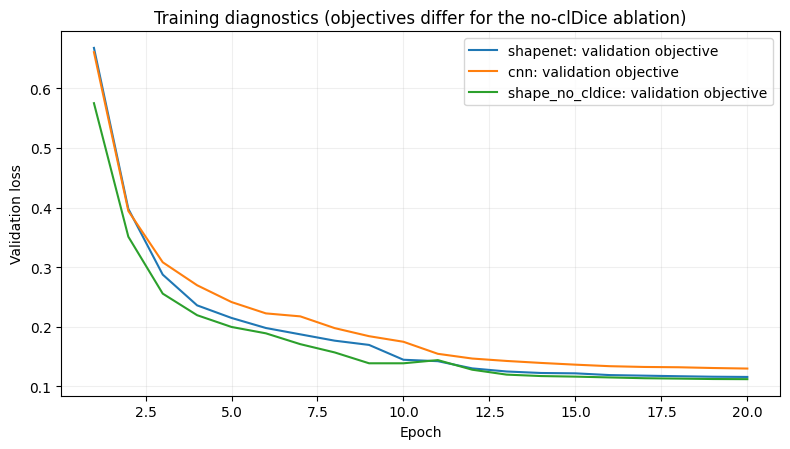

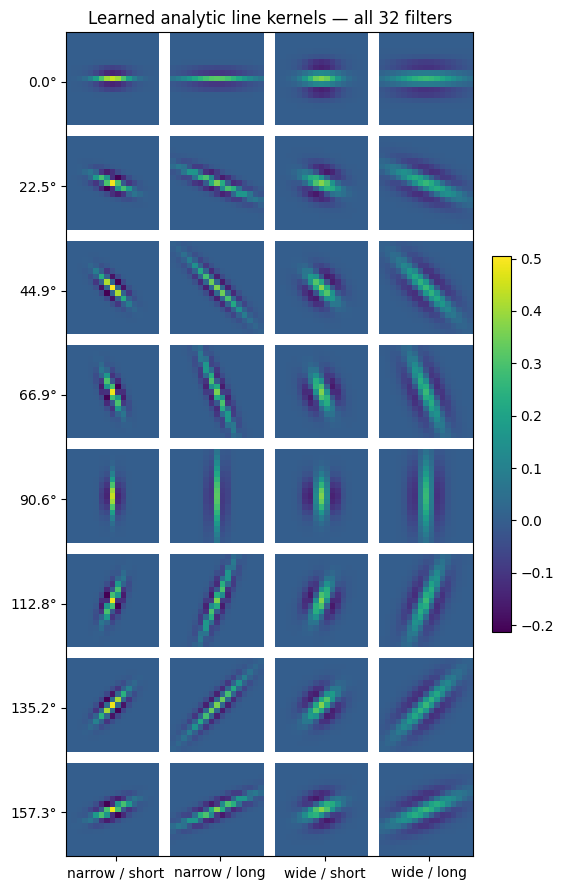

,filter_id,initial_angle_deg,final_angle_deg,initial_width,final_width,initial_length,final_length
0,0,0.0,0.014400,0.75,0.7430,2.3,2.2764
1,1,0.0,0.014400,0.75,0.7556,4.3,4.3996
2,2,0.0,0.014400,1.35,1.3360,2.3,2.3392
3,3,0.0,0.014400,1.35,1.3274,4.3,4.4388
4,4,22.5,22.497101,0.75,0.7543,2.3,2.3219
5,5,22.5,22.497101,0.75,0.7580,4.3,4.3132
6,6,22.5,22.497101,1.35,1.3441,2.3,2.2980
7,7,22.5,22.497101,1.35,1.3731,4.3,4.4514
8,8,45.0,44.867100,0.75,0.7292,2.3,2.2707
9,9,45.0,44.867100,0.75,0.7522,4.3,4.2092


PASS: distinct splits, valid labels, exact line-kernel constraints, loop tracing, empty decoding, geometric gradients.
Analytic-parameter gradient norms: {'angle_offset': 0.058996304869651794, 'raw_sigma': 0.06500913947820663, 'raw_length': 0.017109638080000877}


116

In [ ]:
plot_training_histories(HISTORIES)
FILTER_TABLE = filter_audit(MODELS['shapenet'], INITIAL_GEOMETRY['shapenet'])
display(FILTER_TABLE.round(4))
GRADIENT_AUDIT = check_implementation(DATA, MODELS['shapenet'])
(OUT/'gradient_audit.json').write_text(json.dumps(GRADIENT_AUDIT, indent=2))

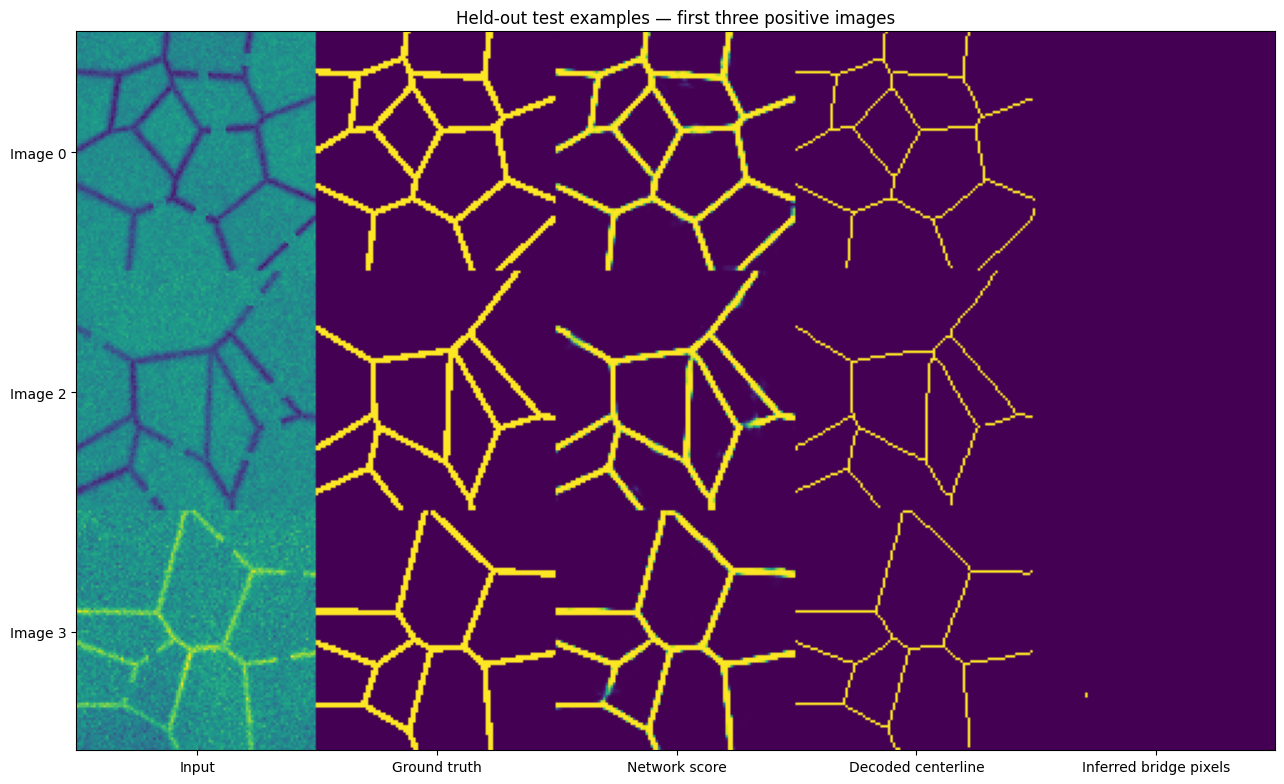

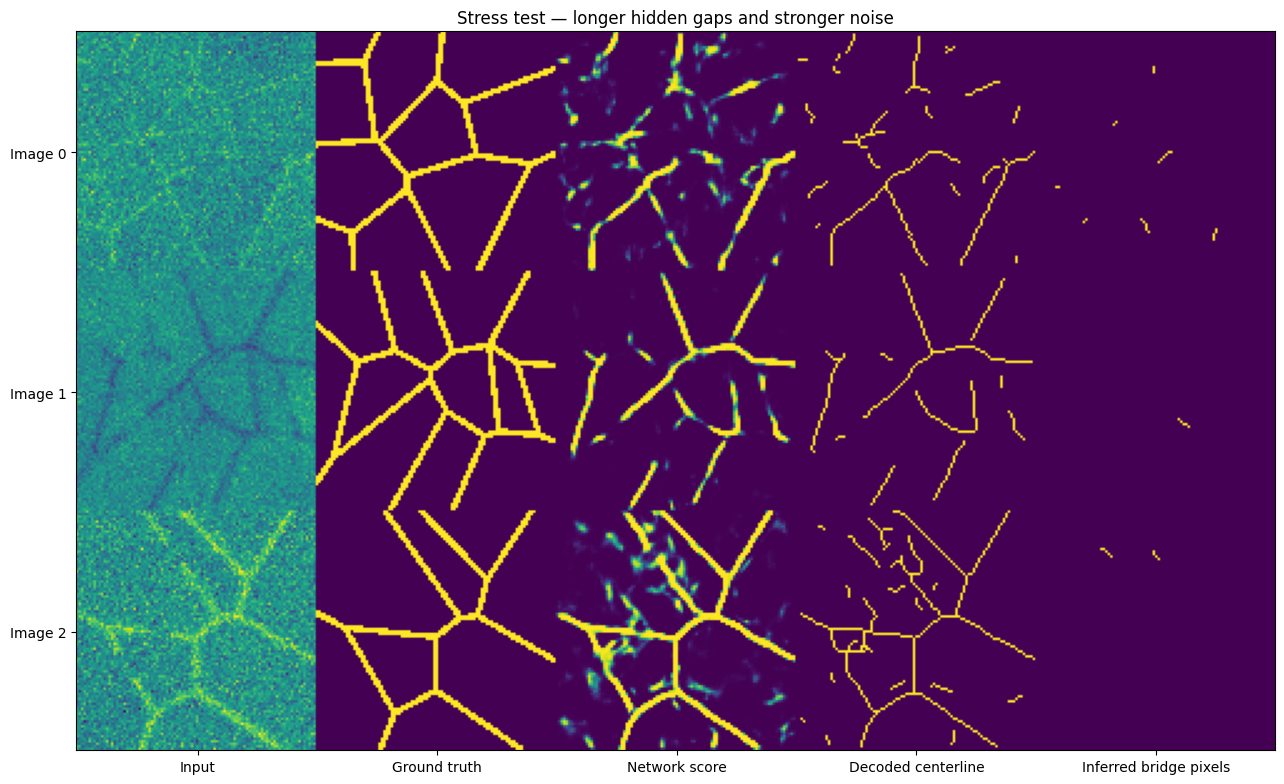

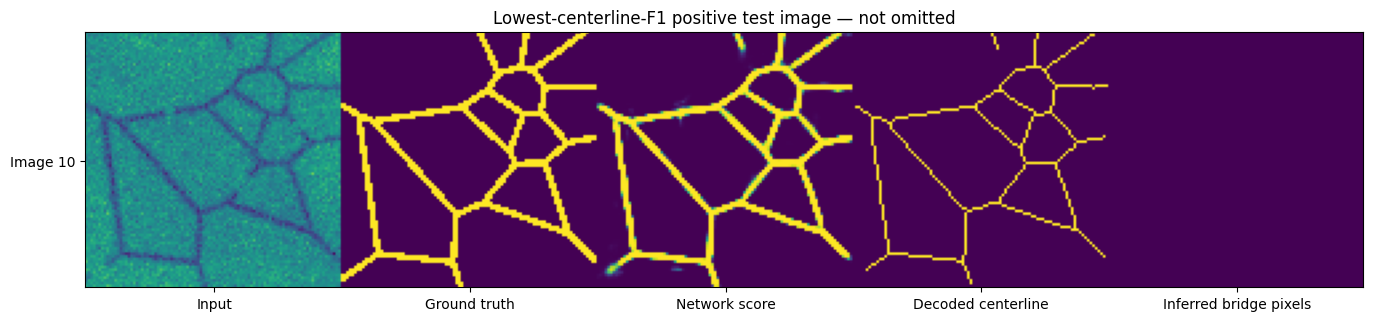

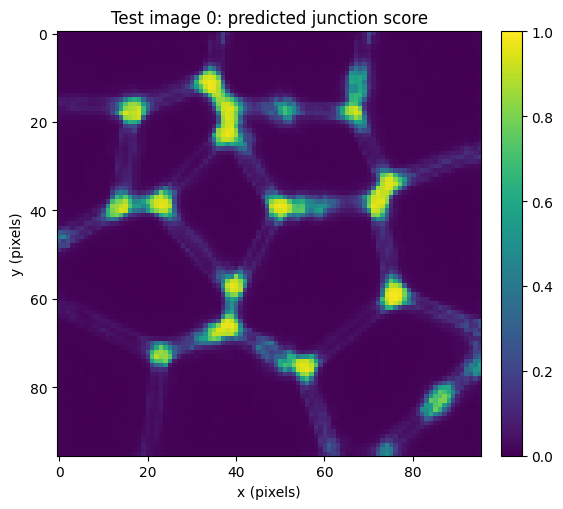

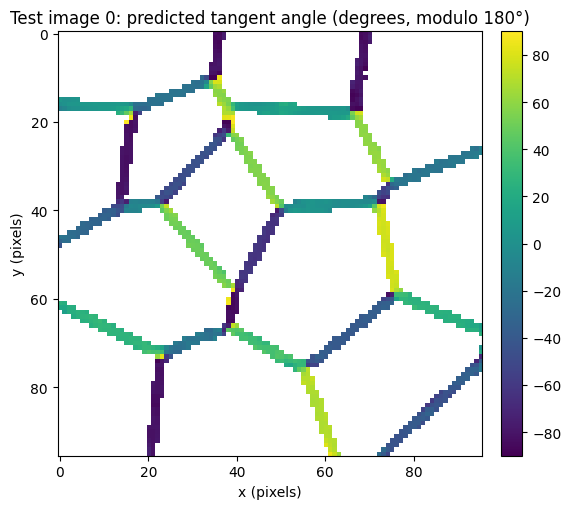

In [ ]:
first_test = np.flatnonzero(~DATA['test']['negative'])[:3].tolist()
plot_prediction_contact_sheet(DATA['test'], PREDICTIONS[('shapenet','test')], DECODED['test'],
    first_test, 'test_examples.png', 'Held-out test examples — first three positive images')
plot_prediction_contact_sheet(DATA['stress'], PREDICTIONS[('shapenet','stress')], DECODED['stress'],
    [0,1,2], 'stress_examples.png', 'Stress test — longer hidden gaps and stronger noise')
positive_test = RESULTS[(RESULTS.model=='shapenet') & (RESULTS.split=='test') & ~RESULTS.negative]
worst_index = int(positive_test.loc[positive_test.centerline_f1.idxmin(), 'index'])
plot_prediction_contact_sheet(DATA['test'], PREDICTIONS[('shapenet','test')], DECODED['test'],
    [worst_index], 'worst_test_example.png', 'Lowest-centerline-F1 positive test image — not omitted')
first = first_test[0]
show_image(PREDICTIONS[('shapenet','test')]['junction'][first],
           f'Test image {first}: predicted junction score', 'predicted_junctions.png', 0, 1)
q = PREDICTIONS[('shapenet','test')]['orientation'][first]
angle = np.degrees(.5*np.arctan2(q[1], q[0]))
angle[PREDICTIONS[('shapenet','test')]['probability'][first] < THRESHOLDS['shapenet']] = np.nan
show_image(angle, f'Test image {first}: predicted tangent angle (degrees, modulo 180°)',
           'predicted_orientation.png', -90, 90)

In [ ]:
COMPARISONS = pd.concat([paired_bootstrap_comparisons(RESULTS, split)
                         for split in ['test','stress']], ignore_index=True)
COMPARISONS.to_csv(OUT/'paired_bootstrap_comparisons.csv', index=False)
display(COMPARISONS.round(5))
# Explicitly report decoder additions rather than assuming they improved topology.
display(SUMMARY[SUMMARY.model=='shapenet_decoded'][['split','accepted_bridges',
    'inferred_pixels','false_inferred_fraction','unresolved_endpoints']].round(5))

,split,metric,comparison,mean_difference,ci_low,ci_high
0,test,dice,shapenet minus cnn,0.00505,0.00345,0.00672
1,test,dice,shapenet minus shape_no_cldice,0.00034,-0.00040,0.00111
2,test,dice,shapenet_decoded minus shapenet,-0.05329,-0.05629,-0.05018
3,test,centerline_f1,shapenet minus cnn,0.00225,0.00127,0.00333
4,test,centerline_f1,shapenet minus shape_no_cldice,0.00080,0.00030,0.00132
5,test,centerline_f1,shapenet_decoded minus shapenet,0.00039,-0.00019,0.00109
6,test,gap_recall,shapenet minus cnn,0.09789,0.06600,0.13322
7,test,gap_recall,shapenet minus shape_no_cldice,0.01785,0.00756,0.03039
8,test,gap_recall,shapenet_decoded minus shapenet,0.01158,0.00138,0.02651
9,test,edge_completeness,shapenet minus cnn,0.02840,0.01804,0.04018


,split,accepted_bridges,inferred_pixels,false_inferred_fraction,unresolved_endpoints
1,test,8,34,0.00000,0.48333
3,stress,93,439,0.34852,26.84375
5,negative,0,0,NaN,NaN


In [ ]:
from IPython.display import Markdown
standard = SUMMARY[(SUMMARY.model=='shapenet') & (SUMMARY.split=='test')].iloc[0]
stress = SUMMARY[(SUMMARY.model=='shapenet') & (SUMMARY.split=='stress')].iloc[0]
standard_decoded = SUMMARY[(SUMMARY.model=='shapenet_decoded') & (SUMMARY.split=='test')].iloc[0]
stress_decoded = SUMMARY[(SUMMARY.model=='shapenet_decoded') & (SUMMARY.split=='stress')].iloc[0]
negative = SUMMARY[(SUMMARY.model=='shapenet') & (SUMMARY.split=='negative')].iloc[0]
display(Markdown(f"""
### Reading the measured result

The ordinary positive test images have **{standard.boundary_dice:.1%} boundary Dice** and
**{standard.centerline_f1:.1%} centerline F1 at a two-pixel tolerance**. Hidden-centerline
recall is **{standard.gap_recall:.1%}** before decoding and **{standard_decoded.gap_recall:.1%}** afterward.
The dedicated negative controls have mean false-positive area **{negative.negative_false_positive_area:.4%}**.

On the more difficult stress distribution, boundary Dice drops to **{stress.boundary_dice:.1%}**
and hidden-centerline recall to **{stress.gap_recall:.1%}**. Decoding changes stress gap recall to
**{stress_decoded.gap_recall:.1%}**, but **{stress_decoded.false_inferred_fraction:.1%} of added bridge pixels**
are farther than two pixels from a true centerline. This last statistic concerns pixels, not the
fraction of whole bridges or graph connections that are wrong.

The decoder leaves an average of **{standard_decoded.unresolved_endpoints:.2f}** unresolved interior
endpoints per ordinary positive test image and **{stress_decoded.unresolved_endpoints:.2f}** per stress
image. Thus the current implementation does **not** guarantee a complete, correctly closed grain network.
These stress failures are preserved in the outputs, not removed from the evaluation.

Rasterized boundary Dice after decoding is **{standard_decoded.boundary_dice:.1%}** on the ordinary test
set, compared with **{standard.boundary_dice:.1%}** before decoding. A thin graph reconstructed with a
fixed-width dilation is a different output representation; improved connectivity should not be
confused with universal improvement in pixel overlap.
"""))


### Reading the measured result

The ordinary positive test images have **94.9% boundary Dice** and
**99.8% centerline F1 at a two-pixel tolerance**. Hidden-centerline
recall is **97.3%** before decoding and **98.5%** afterward.
The dedicated negative controls have mean false-positive area **0.0000%**.

On the more difficult stress distribution, boundary Dice drops to **69.6%**
and hidden-centerline recall to **42.0%**. Decoding changes stress gap recall to
**46.9%**, but **34.9% of added bridge pixels**
are farther than two pixels from a true centerline. This last statistic concerns pixels, not the
fraction of whole bridges or graph connections that are wrong.

The decoder leaves an average of **0.48** unresolved interior
endpoints per ordinary positive test image and **26.84** per stress
image. Thus the current implementation does **not** guarantee a complete, correctly closed grain network.
These stress failures are preserved in the outputs, not removed from the evaluation.

Rasterized boundary Dice after decoding is **89.5%** on the ordinary test
set, compared with **94.9%** before decoding. A thin graph reconstructed with a
fixed-width dilation is a different output representation; improved connectivity should not be
confused with universal improvement in pixel overlap.


## 10. Apply the trained network to a new image

The interface below accepts a finite grayscale array in [0,1] and returns full-field boundary, tangent, and junction maps. Larger images are evaluated with overlapping tiles and blended outputs. Tiling and a changed image scale can alter predictions; inspect these effects before quantitative use.

The optional loader uses 1st/99th-percentile intensity scaling. This is a convenience for an unfamiliar image, **not validated domain adaptation**. Real microscopy may need different scale normalization, contrast modeling, synthetic rendering, and real-image fine-tuning. Grain boundaries visible only as a texture or lattice-orientation change require a different or augmented front end.

No external image is required for the notebook to complete. The demonstration uses an untouched test image. A comparison with the earlier batched prediction is printed as a diagnostic, not used as a stopping assertion. Decoding uses the fresh prediction. Nonfinite fresh outputs still raise an error. A mismatch does not diagnose its own cause; rerun Section 8 if the model or data have changed.

**Section 10 patch:** training, learned weights, thresholds, decoder, and earlier evaluation code are unchanged. Earlier saved outputs are retained from the uploaded notebook; outputs from this modified section onward are cleared and must be regenerated by running those cells.

In [ ]:
example_prediction = predict_full_image(MODELS['shapenet'], DATA['test']['image'][first])
# A cached/batched comparison is diagnostic, not a requirement for decoding.
# Stop for invalid fresh outputs, but do not abort solely on a cache mismatch.
for name, values in example_prediction.items():
    if not np.isfinite(values).all():
        raise ValueError(f"Fresh {name} prediction contains NaN or infinity.")

fresh = example_prediction['probability']
cached = PREDICTIONS[('shapenet', 'test')]['probability'][first]
if fresh.shape == cached.shape and np.isfinite(cached).all():
    max_difference = float(np.max(np.abs(fresh - cached)))
    print(f"Fresh/cached maximum probability difference: {max_difference:.6g}")
    if not np.allclose(fresh, cached, atol=2e-5):
        print("WARNING: predictions differ; continuing with the fresh prediction. "
              "This does not identify the cause. If the model or data changed, "
              "rerun Section 8 to refresh the evaluation results.")
else:
    print("WARNING: cached prediction has an incompatible shape or invalid values. "
          "Continuing with the fresh prediction; rerun Section 8 to refresh evaluation.")
example_decoded = decode_boundaries(example_prediction['probability'],
    example_prediction['orientation'], example_prediction['junction'], THRESHOLDS['shapenet'])
example_graph = skeleton_to_graph(example_decoded['skeleton'], example_decoded['added'])
(OUT/'example_graph.json').write_text(json.dumps(example_graph, indent=2))
print('Example graph:', len(example_graph['nodes']), 'nodes;',
      len(example_graph['edges']), 'continuous polylines;',
      len(example_decoded['unresolved_endpoints']), 'unresolved interior endpoints.')

REAL_IMAGE_PATH = None  # e.g. 'my_micrograph.tif'; change only when an image is available.
if REAL_IMAGE_PATH is not None:
    real_image = load_grayscale(REAL_IMAGE_PATH)
    real_prediction = predict_full_image(MODELS['shapenet'], real_image)
    real_decoded = decode_boundaries(real_prediction['probability'], real_prediction['orientation'],
                                    real_prediction['junction'], THRESHOLDS['shapenet'])
    np.savez_compressed(OUT/'real_image_prediction.npz', **real_prediction,
                        skeleton=real_decoded['skeleton'], added=real_decoded['added'])
    (OUT/'real_image_graph.json').write_text(json.dumps(
        skeleton_to_graph(real_decoded['skeleton'], real_decoded['added']), indent=2))
    show_image(real_prediction['probability'], 'New image: boundary score', 'real_image_score.png', 0, 1)
    show_image(real_decoded['skeleton'], 'New image: decoded centerline', 'real_image_centerline.png', 0, 1)

Fresh/cached maximum probability difference: 0.000899792
Example graph: 26 nodes; 28 continuous polylines; 0 unresolved interior endpoints.


## 11. Interpretation and limitations

This notebook implements the full synthetic-data-to-network workflow, with an explicit distinction between image evidence and geometric completion. It produces reusable labels, trained models, scores, a boundary graph, and quantified failure diagnostics.

A useful outcome is not just high Dice. Check whether the model recovers hidden boundaries without generating boundaries on negative controls; whether the connectivity term helps on paired held-out images; and whether the decoder's extra bridges reduce missing edges without increasing false connections. A CNN or the no-clDice model may match or exceed the full ShapeNet on some metrics. The numerical results, not the architectural hypothesis, determine that conclusion.

The current test does not include realistic curved grain morphologies, triple-junction force balance, pores, multi-phase contrast, etch artifacts, or boundaries defined solely by crystallographic misorientation. Voronoi partitions are a controlled geometric training model, not a universal physical model of grain growth. Real-data claims require real annotations and independent real-image evaluation.

Continuity is exact for each exported polyline and each accepted bridge, but the whole predicted network can still have missing edges, incorrect junctions, or unresolved ends. The decoder is conservative and local, not a global constraint solver enforcing a complete tessellation. Raw sigmoid scores and confidence-looking heat maps are not uncertainty estimates.

### Exported deliverables

The `day25_outputs/` directory contains all split arrays and geometric labels, trained checkpoints, training histories, validation threshold sweeps, per-image and aggregate metrics, paired bootstrap intervals, complete predicted score maps, decoded centerlines, bridge audit records, graph JSON, filter parameters, runtime versions, configuration, and figures. The notebook can regenerate every one of these from scratch.

### Technical references

1. Shit et al., **clDice — A Novel Topology-Preserving Loss Function for Tubular Structure Segmentation**, CVPR 2021. [Primary paper](https://openaccess.thecvf.com/content/CVPR2021/html/Shit_clDice_-_A_Novel_Topology-Preserving_Loss_Function_for_Tubular_Structure_CVPR_2021_paper.html); [authors' code](https://github.com/jocpae/clDice).
2. PyTorch, [functional conv2d documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.conv2d.html). The kernel tensors are constructed differentiably before convolution.
3. scikit-image, [hysteresis thresholding](https://scikit-image.org/docs/stable/api/skimage.filters.html) and [skeletonization](https://scikit-image.org/docs/stable/api/skimage.morphology.html).

The generator, compact network assembly, experimental controls, bridge decoder, and export workflow in this notebook were implemented for ATHENA Hackathon Day 25. This experiment does not use the unrelated 3D CAD benchmark commonly called ShapeNet.

In [ ]:
export_manifest = pd.DataFrame([{'file': p.name, 'bytes': p.stat().st_size}
                               for p in sorted(OUT.iterdir()) if p.is_file()])
export_manifest.to_csv(OUT/'export_manifest.csv', index=False)
print('Outputs:', OUT.resolve())
print('Total files:', len(export_manifest))
display(export_manifest)

Outputs: /content/day25_outputs
Total files: 63


,file,bytes
0,calibration.json,259
1,cnn.pt,97173
2,cnn_history.csv,3699
3,cnn_junction_threshold_selection.csv,396
4,cnn_negative_predictions.npz,3103225
...,...,...
58,training_curves.png,76273
59,val.npz,5080863
60,val_geometry.json,212144
61,versions.json,162
